# Notebook 02 — Modelado, simulación y optimización del calendario

**Proyecto:** Optimización de calendario y maximización de puntos ATP para tenistas profesionales argentinos
**Autor:** Sebastian Losinno · Licenciatura en Ciencia de Datos · Universidad CAECE
**Repositorio:** https://github.com/sebadenos/proyecto-final-tenis · **Corte de datos:** 19/10/2026

**Objetivo.** Responder la pregunta del proyecto: qué calendario de torneos maximiza los puntos ATP esperados de un jugador argentino de ranking 100–300. El trabajo tiene tres etapas:

1. **Modelo de probabilidad de victoria** de cada partido con atributos previos al partido, evaluado contra el baseline Elo recalibrado y los objetivos reformulados en la notebook 01 (sección 9.1).
2. **Simulación de Monte Carlo** de los cuadros, que traduce probabilidades en puntos ATP esperados, validada contra los puntos reales de 2024–2026.
3. **Optimización del calendario** semana a semana, comparada con los calendarios que los jugadores jugaron y con la heurística de la propuesta inicial.

**Reproducibilidad.** Los insumos son las salidas de la notebook 01, publicadas en el repositorio (`data/procesados`). La notebook corre de principio a fin en Google Colab, sin pasos manuales, en unos 10 minutos.

**Estructura:** 0 Configuración · 1 Datos y limpieza previa · 2 Atributos · 3 Modelado · 4 Evaluación en test · 5 Simulación de Monte Carlo · 6 Optimización del calendario · 7 Conclusiones

## 0. Configuración

In [1]:
# 0.1 Parámetros, librerías y descarga de insumos

import time, warnings, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import requests
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, confusion_matrix, precision_recall_fscore_support
import xgboost as xgb
import lightgbm as lgb
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

# Repositorio del proyecto: salidas de la notebook 01 (data/procesados)
REPO = 'sebadenos/proyecto-final-tenis'
URL_REPO = f'https://raw.githubusercontent.com/{REPO}/main'
FECHA_CORTE = pd.Timestamp('2026-10-19')

BASE_DIR = Path('proyecto_final_tenis')
PROC_DIR = BASE_DIR / 'data_procesados'
OUT_DIR = BASE_DIR / 'outputs_02'
FIG_DIR = OUT_DIR / 'figuras'
for carpeta in (PROC_DIR, OUT_DIR, FIG_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

def descargar_del_repo(ruta, destino):
    """Descarga un archivo del repositorio del proyecto, salvo que ya esté en disco."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    destino.parent.mkdir(parents=True, exist_ok=True)
    if URL_REPO.startswith('http'):
        r = requests.get(f'{URL_REPO}/{ruta}', timeout=180)
        r.raise_for_status()
        destino.write_bytes(r.content)
    else:                                   # ejecución desde una copia local del repositorio
        shutil.copy(Path(URL_REPO) / ruta, destino)
    return destino

INSUMOS = ['base_partidos', 'torneos_info', 'puntos', 'paises', 'calendario_2026']
RUTAS = {n: descargar_del_repo(f'data/procesados/{n}.parquet', PROC_DIR / f'{n}.parquet') for n in INSUMOS}

# Alcance (mismos valores que la notebook 01)
TRAIN, VALID, TEST = (2007, 2021), (2022, 2023), (2024, 2026)
RANK_MIN, RANK_MAX = 100, 300
PAIS_FOCO = 'ARG'
RANK_CENTINELA = 3000
SEED = 42
rng_global = np.random.default_rng(SEED)
print(f'Entorno listo. Pandas {pd.__version__} | XGBoost {xgb.__version__} | LightGBM {lgb.__version__}')

Entorno listo. Pandas 2.2.3 | XGBoost 3.4.1 | LightGBM 4.7.0


In [2]:
# 0.2 Estilo gráfico y funciones auxiliares (mismos criterios que la notebook 01)

C_PRINCIPAL, C_SECUNDARIO, C_FOCO, C_GRIS = '#1f5f7a', '#a9c9d6', '#d9822b', '#8c8c8c'
CIRCUITOS = ['ATP cuadro principal', 'Challenger', 'Qualy ATP']
PALETA_CIRCUITO = dict(zip(CIRCUITOS, ['#1f5f7a', '#5fa8a0', '#c9a227']))
SUPERFICIES = ['Clay', 'Hard', 'Grass', 'Carpet']
PALETA_SUP = {'Clay': '#c0603a', 'Hard': '#3b6fa0', 'Grass': '#5b9a4b', 'Carpet': '#8c7aa9'}
NOMBRE_SUP = {'Clay': 'Polvo de ladrillo', 'Hard': 'Cemento', 'Grass': 'Césped', 'Carpet': 'Carpeta'}
STATS = ['ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', 'SvGms', 'bpSaved', 'bpFaced']
TRAMOS = [0, 100, 300, 600, np.inf]
ETIQ_TRAMOS = ['1–100', '101–300', '301–600', '>600']

sns.set_theme(style='white', context='notebook')
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'axes.labelcolor': '#333333', 'xtick.color': '#555555', 'ytick.color': '#555555',
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.alpha': 0.25,
    'figure.dpi': 110, 'savefig.dpi': 150, 'legend.frameon': False,
})

def cerrar(nombre, fuente='Fuente: TennisMyLife (ATP, Challenger y Qualy ATP), elaboración propia.'):
    fig = plt.gcf()
    plt.tight_layout()
    fig.text(0.01, -0.01, fuente, fontsize=8, color=C_GRIS, ha='left', va='top')
    fig.savefig(FIG_DIR / f'{nombre}.png', bbox_inches='tight')
    plt.show()

def pct_axis(ax, axis='y', decimales=0):
    fmt = mtick.PercentFormatter(1.0, decimals=decimales)
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(fmt)

def ic95(s):
    """Semiancho del intervalo de confianza del 95% para una media."""
    s = pd.Series(s).dropna()
    return 1.96 * s.std(ddof=1) / np.sqrt(len(s)) if len(s) > 1 else np.nan

def barras_apiladas(ax, ct, colores, etiquetas=None, umbral=.06):
    """Barras horizontales 100% apiladas con etiquetas directas."""
    izq = np.zeros(len(ct))
    for c in ct.columns:
        vals = ct[c].fillna(0).values
        ax.barh([str(i) for i in ct.index], vals, left=izq, color=colores[c],
                label=(etiquetas or {}).get(c, c), height=.62)
        for y, (l, v) in enumerate(zip(izq, vals)):
            if v > umbral:
                ax.text(l + v / 2, y, f'{v:.0%}', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
        izq += vals
    ax.set_xlim(0, 1); pct_axis(ax, 'x'); ax.grid(False)
    ax.legend(ncol=min(4, len(ct.columns)), loc='upper center', bbox_to_anchor=(.5, -.12), fontsize=8)

def apilar(d, variables):
    """Pasa variables winner_*/loser_* a una única columna (una fila por jugador-partido)."""
    partes = []
    for p in ('winner', 'loser'):
        x = d[['circuito', 'anio'] + [f'{p}_{v}' for v in variables]].copy()
        x.columns = ['circuito', 'anio'] + variables
        partes.append(x)
    return pd.concat(partes, ignore_index=True)

def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

## 1. Datos y limpieza previa

Se parte de la base depurada de la notebook 01 y se resuelven los dos pendientes de limpieza:

- **Evento unificado.** La qualy y el cuadro principal de un mismo torneo son un único evento para cada jugador. Sin esto, un clasificado figura como recién llegado al cuadro principal y su descanso y su carga quedan mal medidos.
- **Descanso acotado.** Los días desde el evento anterior se acotan a un año: las pausas de varios años (lesiones, retiros temporales) no agregan información y distorsionan la escala.

In [3]:
# 1.1 Carga de la base depurada y de las tablas externas

df = pd.read_parquet(RUTAS['base_partidos']).sort_values('match_uid').reset_index(drop=True)
torneos_info = pd.read_parquet(RUTAS['torneos_info'])
puntos = pd.read_parquet(RUTAS['puntos']).set_index('categoria_puntos')
paises = pd.read_parquet(RUTAS['paises'])
calendario_2026 = pd.read_parquet(RUTAS['calendario_2026'])

df['id_atp'] = df.tourney_id.astype(str).str.split('-', n=1).str[1].str.lstrip('0')
df['bo5'] = df.best_of.eq(5).astype(int)
REGION_POR_IOC = paises.dropna(subset=['ioc']).drop_duplicates('ioc').set_index('ioc').region
PAIS_TORNEO = torneos_info.drop_duplicates('id_atp').set_index('id_atp').pais_ioc

print(f'Partidos: {len(df):,} ({df.anio.min()}–{df.anio.max()}) | Torneos con país: {torneos_info.pais_ioc.notna().sum():,} '
      f'| Calendario 2026: {len(calendario_2026):,} torneos')
display(df.groupby('circuito').agg(partidos=('match_uid', 'size'), desde=('anio', 'min'), hasta=('anio', 'max')))

Partidos: 223,190 (2000–2026) | Torneos con país: 879 | Calendario 2026: 327 torneos


,partidos,desde,hasta
circuito,,,
ATP cuadro principal,72609,2000,2026
Challenger,121205,2000,2026
Qualy ATP,29376,2007,2026


In [4]:
# 1.2 Formato jugador-partido y evento unificado (qualy + cuadro principal)
# Cada jugador-torneo es un único evento: la qualy y el cuadro principal de un mismo torneo comparten tourney_id, pero
# en los Grand Slams la qualy tiene fecha de la semana anterior. La fecha del evento es la del primer partido del
# jugador en ese torneo, así un clasificado no figura como "descansado" al entrar al cuadro principal.

BASE = ['match_uid', 'tourney_id', 'id_atp', 'tourney_date', 'anio', 'circuito', 'es_qualy', 'surface', 'surface_elo',
        'orden_ronda', 'round', 'best_of', 'bo5', 'draw_size']
JUG = ['id', 'name', 'seed', 'entry', 'hand', 'ht', 'ioc', 'age', 'rank', 'rank_points']

def perspectiva(d, yo, rival, s_yo, s_rival, gano):
    x = d[BASE].copy()
    for v in JUG:
        x[v] = d[f'{yo}_{v}'].values
    x['opp_id'] = d[f'{rival}_id'].values
    x['svpt'] = d[f'{s_yo}_svpt'].values
    x['sv_won'] = (d[f'{s_yo}_1stWon'] + d[f'{s_yo}_2ndWon']).values
    x['opp_svpt'] = d[f'{s_rival}_svpt'].values
    x['opp_sv_won'] = (d[f'{s_rival}_1stWon'] + d[f'{s_rival}_2ndWon']).values
    x['gano'] = gano
    return x

L = (pd.concat([perspectiva(df, 'winner', 'loser', 'w', 'l', 1), perspectiva(df, 'loser', 'winner', 'l', 'w', 0)],
               ignore_index=True)
     .sort_values(['match_uid', 'gano'], ascending=[True, False]).reset_index(drop=True))
L['entry'] = L.entry.fillna('Directa')

# Evento = jugador × torneo
L['fecha_evento'] = L.groupby(['id', 'tourney_id']).tourney_date.transform('min')
L['partidos_en_evento'] = L.groupby(['id', 'tourney_id']).cumcount()          # partidos previos en el mismo torneo
ev = (L.groupby(['id', 'tourney_id'], sort=False)
       .agg(fecha_evento=('fecha_evento', 'first'), primer_uid=('match_uid', 'min'), partidos=('match_uid', 'size'))
       .reset_index().sort_values(['id', 'fecha_evento', 'primer_uid']).reset_index(drop=True))

# Descanso: días desde el evento anterior del jugador, acotado a un año (hay pausas de varios años por lesiones)
TOPE_DESCANSO = 365
ev['dias_descanso'] = ev.groupby('id').fecha_evento.diff().dt.days
ev['primer_evento'] = ev.dias_descanso.isna().astype(int)
ev['dias_descanso'] = ev.dias_descanso.fillna(TOPE_DESCANSO).clip(upper=TOPE_DESCANSO)
ev['inactivo_8s'] = (ev.dias_descanso > 56).astype(int)

# Carga: partidos jugados en los 30 y 90 días previos al evento (sin contar el propio torneo)
dias_ev = ev.fecha_evento.values.astype('datetime64[D]').astype(np.int64)
carga30, carga90 = np.zeros(len(ev)), np.zeros(len(ev))
for _, idx in ev.groupby('id', sort=False).indices.items():
    t, acum = dias_ev[idx], np.concatenate([[0], np.cumsum(ev.partidos.values[idx])])
    i_ini = np.searchsorted(t, t, 'left')
    carga30[idx] = acum[i_ini] - acum[np.searchsorted(t, t - 30, 'left')]
    carga90[idx] = acum[i_ini] - acum[np.searchsorted(t, t - 90, 'left')]
ev['partidos_30d'], ev['partidos_90d'] = carga30, carga90

L = L.merge(ev[['id', 'tourney_id', 'dias_descanso', 'primer_evento', 'inactivo_8s', 'partidos_30d', 'partidos_90d']],
            on=['id', 'tourney_id'], how='left')
print(f'Jugador-partido: {len(L):,} | Eventos jugador-torneo: {len(ev):,}')
display(ev[['dias_descanso', 'partidos_30d', 'partidos_90d']].describe(percentiles=[.25, .5, .75, .95]).T.round(1))

Jugador-partido: 446,380 | Eventos jugador-torneo: 228,075


,count,mean,std,min,25%,50%,75%,95%,max
dias_descanso,228075.0,41.2,82.6,0.0,7.0,14.0,28.0,302.0,365.0
partidos_30d,228075.0,3.3,3.0,0.0,1.0,3.0,5.0,9.0,23.0
partidos_90d,228075.0,9.6,6.6,0.0,4.0,9.0,14.0,21.0,42.0


## 2. Atributos previos al partido

Todos los atributos usan solo información disponible antes del partido. Siguen la devolución del Hito 2 (inactividad, forma reciente y edad) y los hallazgos del EDA:

| Familia | Atributos |
|---|---|
| Nivel | Elo general y por superficie (ajustado en validación), log(ranking) e indicador de ranking faltante, experiencia |
| Inactividad y carga | Días de descanso (acotados), más de 8 semanas sin jugar, primer torneo, partidos en 30 y 90 días, partidos previos en el mismo torneo |
| Forma reciente | Sobre-rendimiento respecto del Elo en los últimos 10 partidos (contraído hacia 0), variación del Elo en 90 días |
| Contexto del jugador | Edad y edad², localía, clasificado, wild card, lucky loser, cabeza de serie, altura, zurdo |
| Saque (modelo B) | Puntos ganados con el saque y con la devolución en las últimas 52 semanas, contraídos hacia la media |
| Contexto del partido | Superficie, circuito, 5 sets, ronda |

**Control de fuga de información.** En las qualys ATP, la fuente registra la cabeza de serie de forma asimétrica: falta en el 84% de los ganadores y en el 74% de los perdedores. Eso filtraría el resultado (en una primera versión daba un AUC irreal en qualys), así que en las qualys no se usa y la fuerza relativa la aporta el ranking. Las estadísticas de saque solo entran como promedios de partidos anteriores y, en el modelo B, desde 2011, cuando la cobertura en Challenger ya es completa.

In [5]:
# 2.1 Elo ajustado
# Se parte del Elo de la notebook 01 (esquema de FiveThirtyEight) y se ajustan dos parámetros en validación:
# - k_mult: escala del factor K (cuánto se mueve el Elo con cada resultado).
# - refuerzo: multiplicador del K en el primer partido después de más de 60 días sin jugar, para que el Elo se
#   actualice más rápido tras una lesión o un parón (la notebook 01 mostró que la inactividad no la captura el Elo).
# El peso relativo del Elo general y del Elo por superficie lo estima directamente cada modelo.

def calcular_elo(d, k_mult=1.0, refuerzo=1.0, pausa=60):
    """Elo general y por superficie previos a cada partido (orden cronológico de d)."""
    codigos, _ = pd.factorize(pd.concat([d.winner_id, d.loser_id], ignore_index=True))
    n = len(d)
    W, Lo = codigos[:n].tolist(), codigos[n:].tolist()
    S = d.surface_elo.map({'Hard': 0, 'Clay': 1, 'Grass': 2}).fillna(0).astype(int).tolist()
    T = d.tourney_date.values.astype('datetime64[D]').astype(np.int64).tolist()
    P = int(codigos.max()) + 1
    elo, cnt, ult = [1500.0] * P, [0] * P, [None] * P
    elo_s, cnt_s = [[1500.0] * 3 for _ in range(P)], [[0] * 3 for _ in range(P)]
    salida = np.empty((n, 6))
    for i in range(n):
        w, l, s, t = W[i], Lo[i], S[i], T[i]
        salida[i] = (elo[w], elo[l], elo_s[w][s], elo_s[l][s], cnt[w], cnt[l])
        fw = refuerzo if (ult[w] is not None and t - ult[w] > pausa) else 1.0
        fl = refuerzo if (ult[l] is not None and t - ult[l] > pausa) else 1.0
        p = 1.0 / (1.0 + 10 ** ((elo[l] - elo[w]) / 400))
        ps = 1.0 / (1.0 + 10 ** ((elo_s[l][s] - elo_s[w][s]) / 400))
        elo[w] += fw * k_mult * 250.0 / ((cnt[w] + 5) ** 0.4) * (1 - p)
        elo[l] -= fl * k_mult * 250.0 / ((cnt[l] + 5) ** 0.4) * (1 - p)
        elo_s[w][s] += fw * k_mult * 250.0 / ((cnt_s[w][s] + 5) ** 0.4) * (1 - ps)
        elo_s[l][s] -= fl * k_mult * 250.0 / ((cnt_s[l][s] + 5) ** 0.4) * (1 - ps)
        cnt[w] += 1; cnt[l] += 1; cnt_s[w][s] += 1; cnt_s[l][s] += 1
        ult[w] = ult[l] = t
    return salida

# Orientación aleatoria fija (jugador A / jugador B) para evaluar sin sesgo de "el primero es el ganador"
SIGNO = np.where(np.random.default_rng(SEED).random(len(df)) < 0.5, 1, -1)
Y_AB = (SIGNO == 1).astype(int)
EN_TRAIN, EN_VALID = df.anio.between(*TRAIN).values, df.anio.between(*VALID).values

def ll_valid_elo(salida):
    X = np.column_stack([salida[:, 0] - salida[:, 1], salida[:, 2] - salida[:, 3]]) * SIGNO[:, None] / 400
    m = LogisticRegression().fit(X[EN_TRAIN], Y_AB[EN_TRAIN])
    return log_loss(Y_AB[EN_VALID], m.predict_proba(X[EN_VALID])[:, 1])

t0 = time.time()
grilla = []
for k_mult in (0.8, 1.0, 1.25):
    for refuerzo in (1.0, 1.5, 2.0):
        grilla.append({'k_mult': k_mult, 'refuerzo': refuerzo, 'log_loss_valid': ll_valid_elo(calcular_elo(df, k_mult, refuerzo))})
grilla = pd.DataFrame(grilla).sort_values('log_loss_valid').reset_index(drop=True)
K_MULT, REFUERZO = grilla.loc[0, ['k_mult', 'refuerzo']]
print(f'Grilla evaluada en {time.time() - t0:.0f} s. Elegido: k_mult = {K_MULT}, refuerzo = {REFUERZO}')
display(grilla.style.hide(axis='index').format({'log_loss_valid': '{:.4f}'})
        .highlight_min(subset=['log_loss_valid'], color='#d9ead3'))

ELO = calcular_elo(df, K_MULT, REFUERZO)
for j, c in enumerate(['winner_elo2', 'loser_elo2', 'winner_elo2_sup', 'loser_elo2_sup', 'winner_n2', 'loser_n2']):
    df[c] = ELO[:, j]

Grilla evaluada en 6 s. Elegido: k_mult = 1.0, refuerzo = 1.0


k_mult,refuerzo,log_loss_valid
1.000000,1.000000,0.6370
1.000000,1.500000,0.6371
1.250000,1.000000,0.6373
1.250000,1.500000,0.6374
0.800000,1.500000,0.6375
1.000000,2.000000,0.6375
0.800000,1.000000,0.6376
0.800000,2.000000,0.6377
1.250000,2.000000,0.6381


In [6]:
# 2.2 Forma reciente, localía y saque histórico (todo con información previa al torneo)

assert (df.match_uid.values == np.arange(len(df))).all()
es_w = L.gano.eq(1).values
uid = L.match_uid.values
L['elo'] = np.where(es_w, df.winner_elo2.values[uid], df.loser_elo2.values[uid])
L['opp_elo'] = np.where(es_w, df.loser_elo2.values[uid], df.winner_elo2.values[uid])
L['elo_sup'] = np.where(es_w, df.winner_elo2_sup.values[uid], df.loser_elo2_sup.values[uid])
L['n_previos'] = np.where(es_w, df.winner_n2.values[uid], df.loser_n2.values[uid])
L['sobre_rend'] = L.gano - 1 / (1 + 10 ** ((L.opp_elo - L.elo) / 400))

# Por jugador, en orden cronológico: posición del primer partido del evento actual
L = L.sort_values(['id', 'match_uid']).reset_index(drop=True)
L['pos'] = L.groupby('id').cumcount()
L['pos_ini_evento'] = L.groupby(['id', 'tourney_id']).pos.transform('min')
dias = L.fecha_evento.values.astype('datetime64[D]').astype(np.int64)
forma10, delta90 = np.zeros(len(L)), np.zeros(len(L))
sv_w, sv_n, rt_w, rt_n = (np.zeros(len(L)) for _ in range(4))
con_stats = L.svpt.gt(0) & L.opp_svpt.gt(0) & L.sv_won.notna() & L.opp_sv_won.notna()
SR = L.sobre_rend.values
SVW, SVN = np.where(con_stats, L.sv_won, 0.0), np.where(con_stats, L.svpt, 0.0)
RTW, RTN = np.where(con_stats, L.opp_svpt - L.opp_sv_won, 0.0), np.where(con_stats, L.opp_svpt, 0.0)
ELO_ARR = L.elo.values
for _, idx in L.groupby('id', sort=False).indices.items():
    ini = L.pos_ini_evento.values[idx]                         # índice (dentro del jugador) del 1er partido del evento
    t = dias[idx]
    c_sr = np.concatenate([[0], np.cumsum(SR[idx])])
    desde = np.maximum(ini - 10, 0)
    n = ini - desde
    forma10[idx] = (c_sr[ini] - c_sr[desde]) / (n + 5)          # contracción hacia 0 con 5 partidos ficticios
    j90 = np.searchsorted(t, t - 90, 'left')                    # primer partido dentro de los últimos 90 días
    delta90[idx] = np.where(ini > j90, ELO_ARR[idx][ini] - ELO_ARR[idx][np.minimum(j90, len(idx) - 1)], 0.0)
    j52 = np.searchsorted(t, t - 364, 'left')                   # ventana de 52 semanas para el saque
    for dst, src in ((sv_w, SVW), (sv_n, SVN), (rt_w, RTW), (rt_n, RTN)):
        c = np.concatenate([[0], np.cumsum(src[idx])])
        dst[idx] = c[ini] - c[np.minimum(j52, ini)]
L['forma_sobre_rend10'], L['forma_elo90'] = forma10, delta90

# Saque y devolución de las últimas 52 semanas, contraídos hacia la media con 200 puntos ficticios
ref = L.anio.between(*TRAIN) & con_stats
MU_SV = (L.sv_won[ref].sum() / L.svpt[ref].sum())
MU_RT = 1 - MU_SV
K_PTS = 200
L['saque_hist'] = (sv_w + K_PTS * MU_SV) / (sv_n + K_PTS)
L['devol_hist'] = (rt_w + K_PTS * MU_RT) / (rt_n + K_PTS)
L['pts_saque_hist'] = sv_n

# Localía: el jugador juega en su país
L['pais_torneo'] = L.id_atp.map(PAIS_TORNEO)
L['es_local'] = (L.ioc.astype(object) == L.pais_torneo.astype(object)).fillna(False).astype(int)
L = L.sort_values(['match_uid', 'gano'], ascending=[True, False]).reset_index(drop=True)

print(f'Media de saque ganado (train): {MU_SV:.3f}')
display(L[['forma_sobre_rend10', 'forma_elo90', 'saque_hist', 'devol_hist', 'es_local']]
        .describe(percentiles=[.05, .5, .95]).T.round(3))

Media de saque ganado (train): 0.622


,count,mean,std,min,5%,50%,95%,max
forma_sobre_rend10,446380.0,-0.018,0.097,-0.525,-0.178,-0.017,0.142,0.432
forma_elo90,446380.0,8.265,59.902,-346.915,-71.497,0.000,117.828,585.651
saque_hist,446380.0,0.621,0.027,0.497,0.578,0.622,0.668,0.753
devol_hist,446380.0,0.378,0.024,0.255,0.339,0.378,0.418,0.483
es_local,446380.0,0.196,0.397,0.000,0.000,0.000,1.000,1.000


In [7]:
# 2.3 Formato A vs. B: una fila por partido con diferencias entre los dos jugadores
# La orientación (quién es A) es aleatoria, así la variable objetivo "gana A" queda balanceada y el modelo es simétrico.

W, Lr = L[L.gano.eq(1)].set_index('match_uid').sort_index(), L[L.gano.eq(0)].set_index('match_uid').sort_index()
assert (W.index.values == np.arange(len(df))).all() and (Lr.index.values == np.arange(len(df))).all()

def es(s, valor):
    return s.astype(object).eq(valor).astype(int)

def atributos_jugador(x):
    """Atributos individuales previos al partido (una fila por jugador-partido)."""
    rank = x['rank'].fillna(RANK_CENTINELA)
    edad = x.age.fillna(x.age.median())
    return pd.DataFrame({
        'elo': x.elo, 'elo_sup': x.elo_sup,
        'log_rank': np.log(rank), 'sin_rank': x['rank'].isna().astype(int),
        'edad': edad, 'edad2': (edad - 26) ** 2,
        'experiencia': np.log1p(x.n_previos),
        'dias_descanso': x.dias_descanso, 'inactivo_8s': x.inactivo_8s, 'primer_evento': x.primer_evento,
        'partidos_30d': x.partidos_30d, 'partidos_90d': x.partidos_90d, 'partidos_en_evento': x.partidos_en_evento,
        'forma_sobre_rend10': x.forma_sobre_rend10, 'forma_elo90': x.forma_elo90,
        'es_local': x.es_local,
        'clasificado': es(x.entry, 'Q'), 'wild_card': es(x.entry, 'WC'),
        'lucky_loser': es(x.entry, 'LL'),
        # En las qualys la fuente registra la cabeza de serie de forma asimétrica (falta más seguido en los ganadores que
        # en los perdedores), lo que filtraría el resultado; ahí no se usa y la fuerza relativa la aporta el ranking.
        'cabeza_serie': (x.seed.notna() & ~x.es_qualy.astype(bool)).astype(int),
        'altura': x.ht.fillna(185), 'zurdo': es(x.hand, 'L'),
        'saque_hist': x.saque_hist, 'devol_hist': x.devol_hist,
    }, index=x.index)

AW, AL = atributos_jugador(W), atributos_jugador(Lr)
ATRIB_JUG = list(AW.columns)
pares = pd.DataFrame({f'd_{c}': (AW[c].values - AL[c].values) * SIGNO for c in ATRIB_JUG})

# Contexto del partido (simétrico)
ctx = df[['anio', 'circuito', 'surface_elo', 'bo5', 'orden_ronda', 'es_qualy', 'tourney_id', 'id_atp', 'match_uid']].copy()
pares['sup_polvo'] = ctx.surface_elo.eq('Clay').astype(int).values
pares['sup_cesped'] = ctx.surface_elo.eq('Grass').astype(int).values
pares['circ_challenger'] = ctx.circuito.eq('Challenger').astype(int).values
pares['circ_qualy'] = ctx.circuito.eq('Qualy ATP').astype(int).values
pares['bo5'] = ctx.bo5.values
pares['ronda'] = ctx.orden_ronda.values
pares['d_elo_x_bo5'] = pares.d_elo * pares.bo5                       # en 5 sets gana más seguido el mejor
pares['y'] = Y_AB

# Metadatos para segmentar la evaluación (no son atributos del modelo)
meta = ctx.copy()
for c in ['id', 'rank', 'ioc', 'elo']:
    meta[f'{c}_A'] = np.where(SIGNO == 1, W[c].astype(object).values, Lr[c].astype(object).values)
    meta[f'{c}_B'] = np.where(SIGNO == 1, Lr[c].astype(object).values, W[c].astype(object).values)
meta['rank_A'], meta['rank_B'] = pd.to_numeric(meta.rank_A), pd.to_numeric(meta.rank_B)
meta['en_poblacion'] = meta.rank_A.between(RANK_MIN, RANK_MAX) | meta.rank_B.between(RANK_MIN, RANK_MAX)
meta['con_arg'] = meta.ioc_A.eq(PAIS_FOCO) | meta.ioc_B.eq(PAIS_FOCO)
meta['particion'] = np.select([ctx.anio.between(*TRAIN), ctx.anio.between(*VALID), ctx.anio.between(*TEST)],
                              ['train', 'valid', 'test'], 'calentamiento')

print(f'Partidos en formato A/B: {len(pares):,} | % gana A: {pares.y.mean():.1%}')
display(meta.groupby('particion').agg(partidos=('match_uid', 'size'), poblacion=('en_poblacion', 'mean'))
        .reindex(['calentamiento', 'train', 'valid', 'test']).style.format({'partidos': '{:,}', 'poblacion': '{:.1%}'}))

Partidos en formato A/B: 223,190 | % gana A: 49.9%


,partidos,poblacion
particion,,
calentamiento,"48,287",65.1%
train,"125,427",68.6%
valid,"19,138",70.0%
test,"30,338",66.6%


## 3. Modelado

Los modelos se entrenan de menor a mayor complejidad (parsimonia):

1. **Elo recalibrado** (baseline de la notebook 01).
2. **Regresión logística** con regularización L2 y variables estandarizadas.
3. **XGBoost** y **LightGBM**, con detención temprana en validación.

Cada algoritmo se entrena en tres versiones, para separar el efecto del período del efecto del saque: atributos sin saque con train 2007–2021 (A), sin saque con train 2011–2021 y con saque con train 2011–2021 (B). Los hiperparámetros se eligen por Log-Loss en validación (2022–2023); el test (2024–2026) se reserva para la sección 4.

In [8]:
# 3.1 Conjuntos de atributos y particiones

CONTEXTO = ['sup_polvo', 'sup_cesped', 'circ_challenger', 'circ_qualy', 'bo5', 'ronda']
F_BASE = ['d_elo', 'd_elo_sup']                                            # baseline: Elo recalibrado
F_SAQUE = ['d_saque_hist', 'd_devol_hist']
F_A = [f'd_{c}' for c in ATRIB_JUG if f'd_{c}' not in F_SAQUE] + ['d_elo_x_bo5'] + CONTEXTO   # modelo A: sin saque
F_B = F_A + F_SAQUE                                                                      # modelo B: con saque

part = meta.particion.values
TR, VA, TE = part == 'train', part == 'valid', part == 'test'
TR11 = TR & (meta.anio.values >= 2011)            # desde 2011 el saque en Challenger tiene cobertura completa (52 semanas)
y = pares.y.values
POB = meta.en_poblacion.values

def metricas(y_true, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p))
    pendiente = LogisticRegression(C=1e6).fit(logit.reshape(-1, 1), y_true).coef_[0][0]
    return {'AUC-ROC': roc_auc_score(y_true, p), 'Log-Loss': log_loss(y_true, p), 'Brier': brier_score_loss(y_true, p),
            'Accuracy': ((p > .5) == y_true).mean(), 'Pendiente calib.': pendiente, 'n': len(y_true)}

print(f'Atributos del modelo A: {len(F_A)} | modelo B: {len(F_B)}')
print(f'Train: {TR.sum():,} partidos (desde 2011: {TR11.sum():,}) | Validación: {VA.sum():,} | Test: {TE.sum():,}')

Atributos del modelo A: 29 | modelo B: 31
Train: 125,427 partidos (desde 2011: 89,145) | Validación: 19,138 | Test: 30,338


In [9]:
# 3.2 Entrenamiento y ajuste en validación (de menor a mayor complejidad)
# Los hiperparámetros se eligen por Log-Loss en validación (2022–2023); el test (2024–2026) no se usa hasta la sección 4.

def ajustar_logistica(cols, filas):
    mejores = []
    for C in (0.01, 0.1, 1.0):
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)).fit(pares.loc[filas, cols], y[filas])
        mejores.append((log_loss(y[VA], m.predict_proba(pares.loc[VA, cols])[:, 1]), C, m))
    return min(mejores, key=lambda t: t[0])

def ajustar_xgb(cols, filas):
    mejores = []
    for prof in (3, 5):
        m = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=prof, subsample=0.8, colsample_bytree=0.8,
                              min_child_weight=50, reg_lambda=1.0, tree_method='hist', eval_metric='logloss',
                              early_stopping_rounds=100, random_state=SEED, n_jobs=-1)
        m.fit(pares.loc[filas, cols], y[filas], eval_set=[(pares.loc[VA, cols], y[VA])], verbose=False)
        mejores.append((log_loss(y[VA], m.predict_proba(pares.loc[VA, cols])[:, 1]), prof, m))
    return min(mejores, key=lambda t: t[0])

def ajustar_lgbm(cols, filas):
    mejores = []
    for hojas in (15, 31):
        m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=hojas, min_child_samples=200,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                               random_state=SEED, n_jobs=-1, verbose=-1)
        m.fit(pares.loc[filas, cols], y[filas], eval_set=[(pares.loc[VA, cols], y[VA])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        mejores.append((log_loss(y[VA], m.predict_proba(pares.loc[VA, cols])[:, 1]), hojas, m))
    return min(mejores, key=lambda t: t[0])

t0 = time.time()
modelos, filas_res = {}, []
ll, C_base, m = ajustar_logistica(F_BASE, TR)
modelos['Elo recalibrado (baseline)'] = (m, F_BASE)
filas_res.append(['Elo recalibrado (baseline)', 'A', '2007–2021', '—', ll])
for nombre, ajustar, hp in [('Regresión logística', ajustar_logistica, 'C'), ('XGBoost', ajustar_xgb, 'profundidad'),
                            ('LightGBM', ajustar_lgbm, 'hojas')]:
    for version, cols, filas, periodo in [('A', F_A, TR, '2007–2021'), ('A', F_A, TR11, '2011–2021'), ('B', F_B, TR11, '2011–2021')]:
        ll, valor, m = ajustar(cols, filas)
        clave = f'{nombre} {version} ({periodo})'
        modelos[clave] = (m, cols)
        filas_res.append([nombre, version, periodo, f'{hp} = {valor}', ll])
res_valid = pd.DataFrame(filas_res, columns=['modelo', 'atributos', 'train', 'hiperparámetro elegido', 'Log-Loss valid'])
res_valid['mejora vs. baseline'] = res_valid['Log-Loss valid'].iloc[0] - res_valid['Log-Loss valid']
print(f'Entrenamiento: {time.time() - t0:.0f} s. A = sin saque histórico, B = con saque histórico.')
display(res_valid.style.hide(axis='index').format({'Log-Loss valid': '{:.4f}', 'mejora vs. baseline': '{:+.4f}'})
        .highlight_min(subset=['Log-Loss valid'], color='#d9ead3'))

Entrenamiento: 51 s. A = sin saque histórico, B = con saque histórico.


modelo,atributos,train,hiperparámetro elegido,Log-Loss valid,mejora vs. baseline
Elo recalibrado (baseline),A,2007–2021,—,0.6370,+0.0000
Regresión logística,A,2007–2021,C = 0.01,0.6284,+0.0086
Regresión logística,A,2011–2021,C = 0.01,0.6275,+0.0095
Regresión logística,B,2011–2021,C = 0.01,0.6263,+0.0107
XGBoost,A,2007–2021,profundidad = 5,0.6256,+0.0114
XGBoost,A,2011–2021,profundidad = 5,0.6251,+0.0119
XGBoost,B,2011–2021,profundidad = 5,0.6240,+0.0130
LightGBM,A,2007–2021,hojas = 15,0.6256,+0.0114
LightGBM,A,2011–2021,hojas = 31,0.6253,+0.0116
LightGBM,B,2011–2021,hojas = 15,0.6240,+0.0130


### 3.3 Sesgo y varianza

Las curvas de aprendizaje comparan el error en train y en validación a medida que crece el conjunto de entrenamiento.

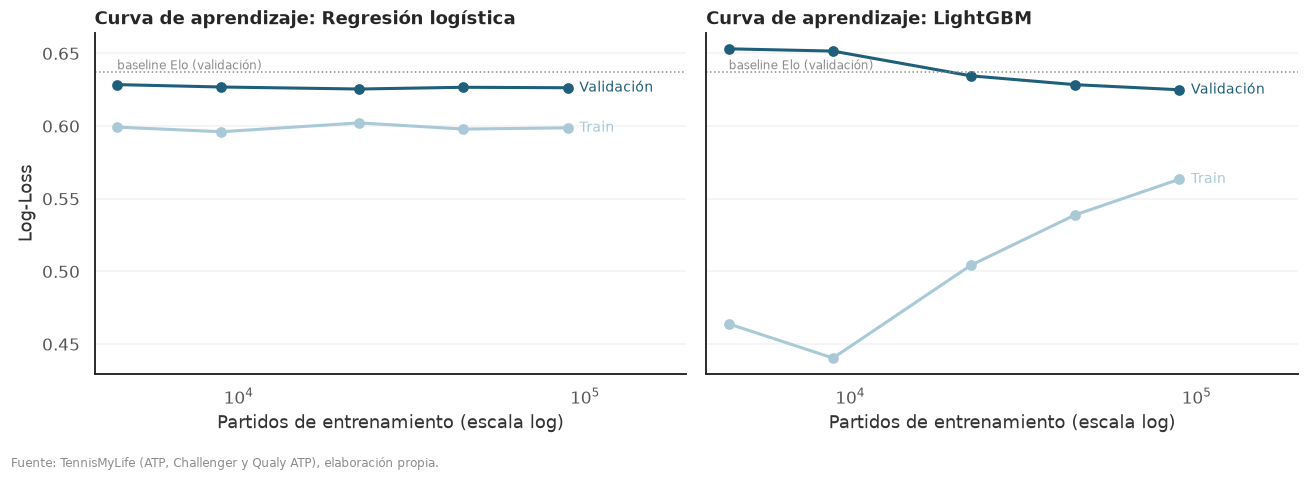

Train                     Validación                    
modelo LightGBM Regresión logística   LightGBM Regresión logística
n                                                                 
4457     0.4639              0.5993     0.6531              0.6285
8914     0.4404              0.5961     0.6515              0.6268
22286    0.5042              0.6021     0.6345              0.6255
44572    0.5389              0.5979     0.6285              0.6267
89145    0.5634              0.5988     0.6249              0.6263

In [10]:
# 3.3 Curvas de aprendizaje: sesgo y varianza
# Se reentrena cada modelo con fracciones crecientes del train y se compara el Log-Loss en train y en validación.
# Una brecha grande indica sobreajuste (varianza); dos curvas altas y juntas, subajuste (sesgo).

m_lgbm, _ = modelos['LightGBM B (2011–2021)']
N_ARBOLES = m_lgbm.best_iteration_
crear = {
    'Regresión logística': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000)),
    'LightGBM': lambda: lgb.LGBMClassifier(n_estimators=N_ARBOLES, learning_rate=0.03, num_leaves=31, min_child_samples=200,
                                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                           random_state=SEED, n_jobs=-1, verbose=-1),
}
idx_tr = np.flatnonzero(TR11)
rng = np.random.default_rng(SEED)
curvas = []
for frac in (0.05, 0.1, 0.25, 0.5, 1.0):
    sub = np.sort(rng.choice(idx_tr, int(len(idx_tr) * frac), replace=False))
    for nombre, f in crear.items():
        m = f().fit(pares.iloc[sub][F_B], y[sub])
        curvas.append({'modelo': nombre, 'n': len(sub),
                       'Train': log_loss(y[sub], m.predict_proba(pares.iloc[sub][F_B])[:, 1]),
                       'Validación': log_loss(y[VA], m.predict_proba(pares.loc[VA, F_B])[:, 1])})
curvas = pd.DataFrame(curvas)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (nombre, d) in zip(axes, curvas.groupby('modelo', sort=False)):
    for col, color in [('Train', C_SECUNDARIO), ('Validación', C_PRINCIPAL)]:
        ax.plot(d.n, d[col], marker='o', lw=2, color=color)
        ax.text(d.n.iloc[-1] * 1.08, d[col].iloc[-1], col, color=color, va='center', fontsize=9)
    ax.axhline(res_valid['Log-Loss valid'].iloc[0], color=C_GRIS, ls=':', lw=1)
    ax.text(d.n.iloc[0], res_valid['Log-Loss valid'].iloc[0] + .002, 'baseline Elo (validación)', color=C_GRIS, fontsize=8)
    ax.set_xscale('log'); ax.set_xlim(None, d.n.iloc[-1] * 2.2)
    ax.set_title(f'Curva de aprendizaje: {nombre}'); ax.set_xlabel('Partidos de entrenamiento (escala log)')
axes[0].set_ylabel('Log-Loss')
cerrar('20_curvas_aprendizaje')
display(curvas.pivot(index='n', columns='modelo', values=['Train', 'Validación']).round(4))

### 3.4 Selección y calibración

Las probabilidades alimentan una simulación ronda por ronda, así que una pequeña sobreconfianza se acumula. Por eso, además de elegir el modelo, se verifica si conviene recalibrarlo.

In [11]:
# 3.4 Selección del modelo y calibración
# Se elige el modelo con menor Log-Loss en validación. Para decidir si conviene recalibrarlo (Platt), el calibrador se
# ajusta en 2022 y se evalúa en 2023; si mejora, el calibrador final se ajusta con toda la validación.

FINAL = 'LightGBM B (2011–2021)'
m_final, cols_final = modelos[FINAL]

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

p_va = m_final.predict_proba(pares.loc[VA, cols_final])[:, 1]
anio_va = meta.anio.values[VA]
cal_2022 = LogisticRegression(C=1e6).fit(logit(p_va[anio_va == 2022]).reshape(-1, 1), y[VA][anio_va == 2022])
ll_crudo = log_loss(y[VA][anio_va == 2023], p_va[anio_va == 2023])
ll_platt = log_loss(y[VA][anio_va == 2023], cal_2022.predict_proba(logit(p_va[anio_va == 2023]).reshape(-1, 1))[:, 1])
USAR_PLATT = ll_platt < ll_crudo - 0.0005
calibrador = LogisticRegression(C=1e6).fit(logit(p_va).reshape(-1, 1), y[VA]) if USAR_PLATT else None

def predecir(X, modelo=m_final, cols=cols_final):
    """Probabilidad de que gane el jugador A según el modelo final (calibrado si corresponde)."""
    p = modelo.predict_proba(X[cols])[:, 1]
    return calibrador.predict_proba(logit(p).reshape(-1, 1))[:, 1] if calibrador is not None else p

print(f'Modelo final: {FINAL} ({N_ARBOLES} árboles)')
print(f'Log-Loss 2023 sin recalibrar: {ll_crudo:.4f} | con Platt ajustado en 2022: {ll_platt:.4f} → '
      + ('se recalibra' if USAR_PLATT else 'no hace falta recalibrar'))
print(f"Pendiente de calibración en validación: {metricas(y[VA], p_va)['Pendiente calib.']:.3f}")

Modelo final: LightGBM B (2011–2021) (592 árboles)
Log-Loss 2023 sin recalibrar: 0.6252 | con Platt ajustado en 2022: 0.6239 → se recalibra
Pendiente de calibración en validación: 0.879


## 4. Evaluación en test (2024–2026)

El test no se usó en ninguna decisión anterior. Se reportan las métricas de la propuesta (AUC-ROC, Log-Loss) junto con el Brier score, la pendiente de calibración y la exactitud, por subconjunto.

In [12]:
# 4.1 Métricas en test (2024–2026), por subconjunto

def prob_modelo(nombre, filas):
    m, cols = modelos[nombre]
    X = pares.loc[filas]
    return predecir(X) if nombre == FINAL else m.predict_proba(X[cols])[:, 1]

COMPARADOS = {'Elo recalibrado (baseline)': 'Elo recalibrado (baseline)', 'Regresión logística': 'Regresión logística B (2011–2021)',
              'XGBoost': 'XGBoost B (2011–2021)', f'LightGBM (final, {"calibrado" if USAR_PLATT else "sin recalibrar"})': FINAL}
P_TEST = {etiqueta: prob_modelo(nombre, TE) for etiqueta, nombre in COMPARADOS.items()}
y_te, meta_te = y[TE], meta[TE].reset_index(drop=True)
SUBCONJ = {'Población objetivo (≥1 jugador 100–300)': meta_te.en_poblacion.values,
           'Todos los partidos': np.ones(len(meta_te), bool),
           'ATP cuadro principal': meta_te.circuito.eq('ATP cuadro principal').values,
           'Challenger': meta_te.circuito.eq('Challenger').values,
           'Qualy ATP': meta_te.circuito.eq('Qualy ATP').values,
           'Con un jugador argentino': meta_te.con_arg.values}
filas = [{'subconjunto': s, 'modelo': mod, **metricas(y_te[mask], p[mask])}
         for s, mask in SUBCONJ.items() for mod, p in P_TEST.items()]
tabla_test = pd.DataFrame(filas)
display(tabla_test.style.hide(axis='index')
        .format({'AUC-ROC': '{:.3f}', 'Log-Loss': '{:.3f}', 'Brier': '{:.3f}', 'Accuracy': '{:.1%}', 'Pendiente calib.': '{:.2f}',
                 'n': '{:,}'})
        .background_gradient(subset=['Log-Loss'], cmap='Greens_r'))

subconjunto,modelo,AUC-ROC,Log-Loss,Brier,Accuracy,Pendiente calib.,n
Población objetivo (≥1 jugador 100–300),Elo recalibrado (baseline),0.685,0.640,0.225,63.6%,0.84,"20,211"
Población objetivo (≥1 jugador 100–300),Regresión logística,0.698,0.631,0.221,64.7%,0.87,"20,211"
Población objetivo (≥1 jugador 100–300),XGBoost,0.698,0.630,0.220,64.5%,0.88,"20,211"
Población objetivo (≥1 jugador 100–300),"LightGBM (final, calibrado)",0.699,0.630,0.220,64.5%,1.01,"20,211"
Todos los partidos,Elo recalibrado (baseline),0.688,0.638,0.223,63.6%,0.86,"30,338"
Todos los partidos,Regresión logística,0.703,0.627,0.219,64.9%,0.88,"30,338"
Todos los partidos,XGBoost,0.703,0.626,0.219,64.7%,0.89,"30,338"
Todos los partidos,"LightGBM (final, calibrado)",0.704,0.625,0.218,64.7%,1.01,"30,338"
ATP cuadro principal,Elo recalibrado (baseline),0.718,0.616,0.214,65.1%,0.93,"7,844"
ATP cuadro principal,Regresión logística,0.728,0.606,0.210,66.7%,0.92,"7,844"


### 4.2 Objetivos reformulados

La comparación central es en la población objetivo contra el baseline, con intervalos de confianza por bootstrap.

In [13]:
# 4.2 Cumplimiento de los objetivos reformulados (notebook 01, sección 9.1), en la población objetivo
# Intervalos de confianza del 95% por bootstrap de partidos (2.000 remuestreos).

mask_pob = SUBCONJ['Población objetivo (≥1 jugador 100–300)']
yp = y_te[mask_pob]
p_base = np.clip(P_TEST['Elo recalibrado (baseline)'][mask_pob], 1e-6, 1 - 1e-6)
p_fin = np.clip(P_TEST[[k for k in P_TEST if k.startswith('LightGBM')][0]][mask_pob], 1e-6, 1 - 1e-6)
perdida = lambda p: -(yp * np.log(p) + (1 - yp) * np.log(1 - p))
d_ll, d_br = perdida(p_fin) - perdida(p_base), (p_fin - yp) ** 2 - (p_base - yp) ** 2
rng = np.random.default_rng(SEED)
boot = rng.integers(0, len(yp), size=(2000, len(yp)))
ic_ll, ic_br = np.percentile(d_ll[boot].mean(1), [2.5, 97.5]), np.percentile(d_br[boot].mean(1), [2.5, 97.5])
m_base, m_fin = metricas(yp, p_base), metricas(yp, p_fin)

objetivos = pd.DataFrame([
    ['Log-Loss', f"{m_base['Log-Loss']:.3f}", f"{m_fin['Log-Loss']:.3f}",
     f"{d_ll.mean():+.4f} [{ic_ll[0]:+.4f}; {ic_ll[1]:+.4f}]", 'Menor, con IC por debajo de 0', ic_ll[1] < 0],
    ['Brier score', f"{m_base['Brier']:.3f}", f"{m_fin['Brier']:.3f}",
     f"{d_br.mean():+.4f} [{ic_br[0]:+.4f}; {ic_br[1]:+.4f}]", 'Menor que el baseline', ic_br[1] < 0],
    ['Pendiente de calibración', f"{m_base['Pendiente calib.']:.2f}", f"{m_fin['Pendiente calib.']:.2f}", '—',
     'Entre 0.90 y 1.10', 0.90 <= m_fin['Pendiente calib.'] <= 1.10],
    ['AUC-ROC', f"{m_base['AUC-ROC']:.3f}", f"{m_fin['AUC-ROC']:.3f}", f"{m_fin['AUC-ROC'] - m_base['AUC-ROC']:+.3f}",
     'Igual o mayor', m_fin['AUC-ROC'] >= m_base['AUC-ROC']],
    ['Referencia: umbrales de la propuesta inicial', 'AUC 0.72 / LL 0.60', f"AUC {m_fin['AUC-ROC']:.3f} / LL {m_fin['Log-Loss']:.3f}",
     '—', 'AUC > 0.72 y Log-Loss < 0.60', m_fin['AUC-ROC'] > 0.72 and m_fin['Log-Loss'] < 0.60],
], columns=['métrica', 'baseline Elo recalibrado', 'modelo final', 'diferencia [IC 95%]', 'objetivo', 'cumple'])
objetivos['cumple'] = objetivos.cumple.map({True: 'Sí', False: 'No'})
display(objetivos.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

métrica,baseline Elo recalibrado,modelo final,diferencia [IC 95%],objetivo,cumple
Log-Loss,0.640,0.630,-0.0108 [-0.0129; -0.0087],"Menor, con IC por debajo de 0",Sí
Brier score,0.225,0.220,-0.0046 [-0.0055; -0.0037],Menor que el baseline,Sí
Pendiente de calibración,0.84,1.01,—,Entre 0.90 y 1.10,Sí
AUC-ROC,0.685,0.699,+0.014,Igual o mayor,Sí
Referencia: umbrales de la propuesta inicial,AUC 0.72 / LL 0.60,AUC 0.699 / LL 0.630,—,AUC > 0.72 y Log-Loss < 0.60,No


### 4.3 Matriz de confusión

Aunque el problema es probabilístico, la matriz de confusión con umbral 0.5 muestra qué tipo de error comete cada modelo desde la perspectiva del jugador de la población.

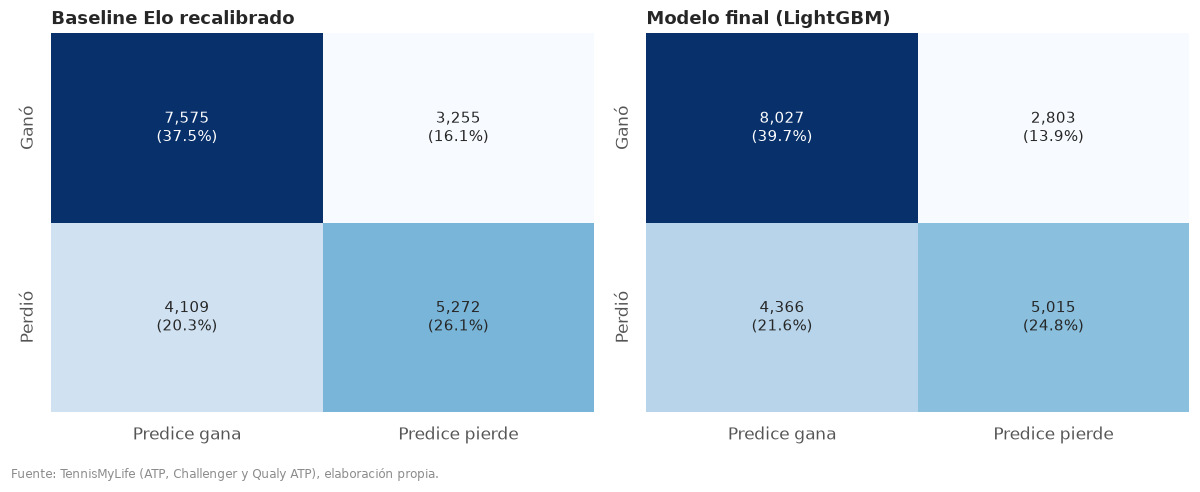

modelo,Accuracy,Precisión,Recall,F1,Falsos positivos,Falsos negativos
Baseline Elo recalibrado,63.6%,64.8%,69.9%,0.673,"4,109","3,255"
Modelo final (LightGBM),64.5%,64.8%,74.1%,0.691,"4,366","2,803"


In [14]:
# 4.3 Matriz de confusión desde la perspectiva del jugador de la población
# Cada partido se mira desde el jugador de ranking 100–300 (si son dos, el jugador A). Los dos errores tienen costos
# distintos para la recomendación de calendario:
# - Falso positivo (se predice que gana y pierde): sobreestima sus puntos esperados → recomienda torneos demasiado exigentes.
# - Falso negativo (se predice que pierde y gana): subestima sus puntos → descarta torneos que le convenían.

es_A = meta_te.rank_A.between(RANK_MIN, RANK_MAX).values[mask_pob]
y_j = np.where(es_A, yp, 1 - yp)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
filas_cm = []
for ax, (nombre, p) in zip(axes, [('Baseline Elo recalibrado', p_base), ('Modelo final (LightGBM)', p_fin)]):
    p_j = np.where(es_A, p, 1 - p)
    pred = (p_j > .5).astype(int)
    cm = confusion_matrix(y_j, pred, labels=[1, 0])
    prec, rec, f1, _ = precision_recall_fscore_support(y_j, pred, average='binary', pos_label=1)
    filas_cm.append({'modelo': nombre, 'Accuracy': (pred == y_j).mean(), 'Precisión': prec, 'Recall': rec, 'F1': f1,
                     'Falsos positivos': cm[1, 0], 'Falsos negativos': cm[0, 1]})
    sns.heatmap(cm / cm.sum(), annot=np.array([[f'{v:,}\n({v / cm.sum():.1%})' for v in fila] for fila in cm]), fmt='',
                cmap='Blues', cbar=False, ax=ax, xticklabels=['Predice gana', 'Predice pierde'],
                yticklabels=['Ganó', 'Perdió'], annot_kws={'fontsize': 10})
    ax.set_title(nombre); ax.set_xlabel(''); ax.set_ylabel('')
cerrar('21_matriz_confusion')
display(pd.DataFrame(filas_cm).style.hide(axis='index')
        .format({'Accuracy': '{:.1%}', 'Precisión': '{:.1%}', 'Recall': '{:.1%}', 'F1': '{:.3f}',
                 'Falsos positivos': '{:,}', 'Falsos negativos': '{:,}'}))

### 4.4 Análisis de errores

Se revisa la calibración por deciles y los residuos por circuito, superficie, tramo de ranking, temporada y, para los argentinos, por superficie: el EDA había mostrado que el Elo general los sobreestima fuera del polvo.

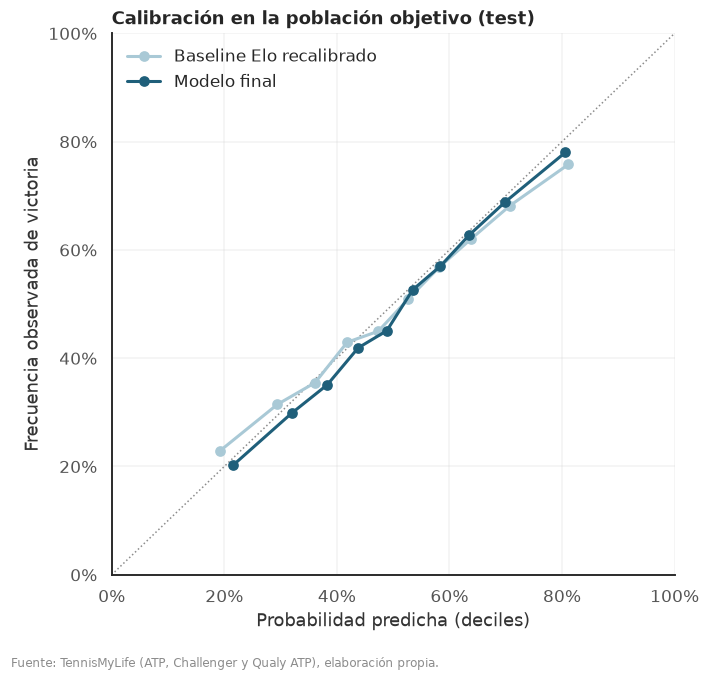

dimensión,segmento,partidos,victorias observadas,residuo baseline,residuo modelo final
Circuito,ATP cuadro principal,"2,575",37.7%,+0.5%,-0.8%
Circuito,Challenger,"14,269",57.1%,+0.0%,-0.9%
Circuito,Qualy ATP,"3,367",50.9%,-0.2%,-1.1%
Superficie,Cemento,"9,578",53.3%,+0.1%,-1.1%
Superficie,Césped,"1,235",48.7%,+0.8%,-0.5%
Superficie,Polvo de ladrillo,"9,398",54.5%,-0.1%,-0.8%
Tramo de ranking,100–150,"6,067",54.6%,-0.5%,-0.8%
Tramo de ranking,151–200,"5,146",54.4%,-1.1%,-1.8%
Tramo de ranking,201–250,"4,845",53.3%,+0.9%,-0.3%
Tramo de ranking,251–300,"4,153",51.5%,+1.1%,-0.7%


In [15]:
# 4.4 Análisis de errores: calibración y residuos (observado − predicho) por segmento
# En clasificación probabilística, el residuo de un grupo es la diferencia entre la proporción de victorias observada y
# la probabilidad media predicha. Un residuo sistemático indica un sesgo que el modelo no captura.

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=C_GRIS, ls=':', lw=1)
for nombre, p, color in [('Baseline Elo recalibrado', p_base, C_SECUNDARIO), ('Modelo final', p_fin, C_PRINCIPAL)]:
    q = pd.qcut(p, 10, duplicates='drop')
    cal = pd.DataFrame({'p': p, 'y': yp}).groupby(q, observed=True).mean()
    ax.plot(cal.p, cal.y, marker='o', lw=2, color=color, label=nombre)
pct_axis(ax, 'x'); pct_axis(ax, 'y'); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, axis='both', alpha=.25)
ax.set_xlabel('Probabilidad predicha (deciles)'); ax.set_ylabel('Frecuencia observada de victoria')
ax.set_title('Calibración en la población objetivo (test)'); ax.legend(loc='upper left')
cerrar('22_calibracion_test')

# Residuos desde la perspectiva del jugador de la población
mt = meta_te[mask_pob].reset_index(drop=True)
seg = pd.DataFrame({
    'y': y_j, 'p_base': np.where(es_A, p_base, 1 - p_base), 'p_final': np.where(es_A, p_fin, 1 - p_fin),
    'Circuito': mt.circuito.values,
    'Superficie': mt.surface_elo.map(NOMBRE_SUP).values,
    'Tramo de ranking': pd.cut(np.where(es_A, mt.rank_A, mt.rank_B), [99, 150, 200, 250, 300],
                               labels=['100–150', '151–200', '201–250', '251–300']).astype(str),
    'Temporada': mt.anio.astype(str).values,
    'Argentinos por superficie': np.where(np.where(es_A, mt.ioc_A, mt.ioc_B) == PAIS_FOCO,
                                          mt.surface_elo.map(NOMBRE_SUP).values, None),
})
filas_r = []
for dim in ['Circuito', 'Superficie', 'Tramo de ranking', 'Temporada', 'Argentinos por superficie']:
    for nivel, g in seg.dropna(subset=[dim]).groupby(dim):
        filas_r.append({'dimensión': dim, 'segmento': nivel, 'partidos': len(g), 'victorias observadas': g.y.mean(),
                        'residuo baseline': (g.y - g.p_base).mean(), 'residuo modelo final': (g.y - g.p_final).mean()})
residuos = pd.DataFrame(filas_r)
display(residuos.style.hide(axis='index')
        .format({'partidos': '{:,}', 'victorias observadas': '{:.1%}', 'residuo baseline': '{:+.1%}', 'residuo modelo final': '{:+.1%}'})
        .background_gradient(subset=['residuo baseline', 'residuo modelo final'], cmap='RdBu', vmin=-.06, vmax=.06))

### 4.5 Interpretación

SHAP muestra qué atributos explican las predicciones y en qué dirección.

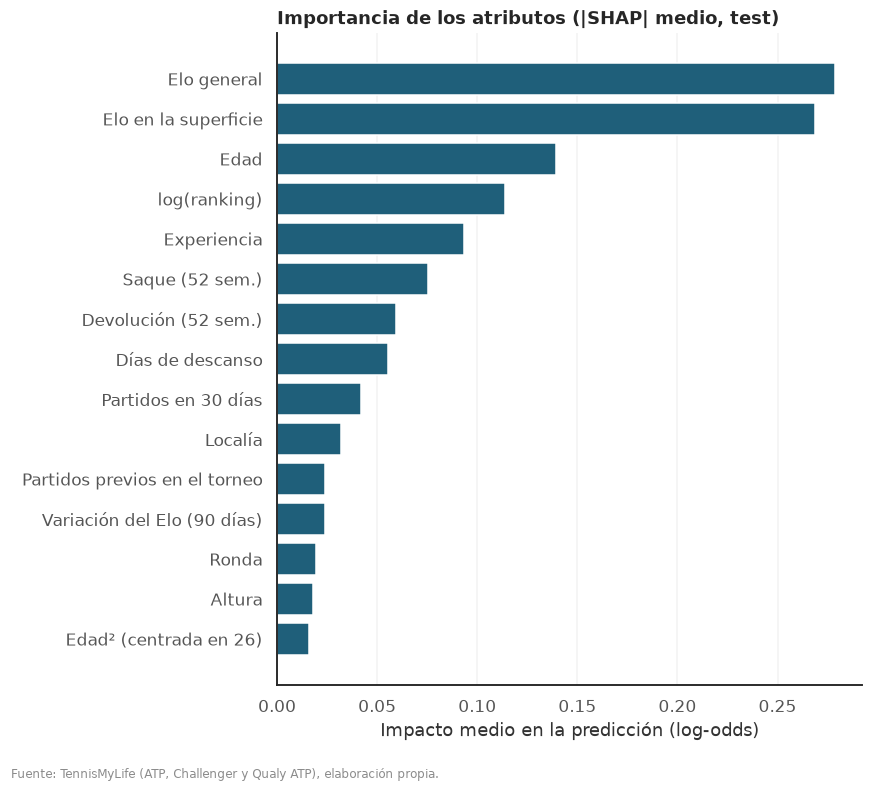

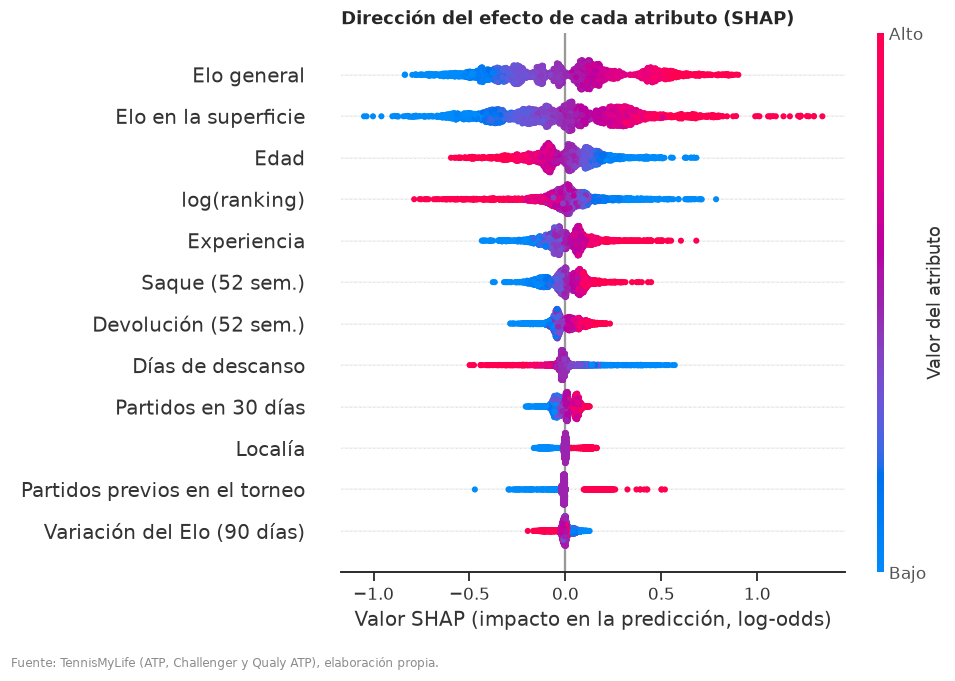

In [16]:
# 4.5 Interpretación del modelo final con SHAP
# Los valores SHAP reparten cada predicción entre los atributos: cuánto empuja cada uno la probabilidad de que gane A.

try:
    import shap
except ImportError:                                     # Colab suele traerlo instalado; si no, se instala
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'], check=True)
    import shap

NOMBRES = {'d_elo': 'Elo general', 'd_elo_sup': 'Elo en la superficie', 'd_log_rank': 'log(ranking)',
           'd_sin_rank': 'Sin ranking', 'd_edad': 'Edad', 'd_edad2': 'Edad² (centrada en 26)', 'd_experiencia': 'Experiencia',
           'd_dias_descanso': 'Días de descanso', 'd_inactivo_8s': 'Más de 8 semanas sin jugar', 'd_primer_evento': 'Primer torneo',
           'd_partidos_30d': 'Partidos en 30 días', 'd_partidos_90d': 'Partidos en 90 días',
           'd_partidos_en_evento': 'Partidos previos en el torneo', 'd_forma_sobre_rend10': 'Sobre-rendimiento (10 partidos)',
           'd_forma_elo90': 'Variación del Elo (90 días)', 'd_es_local': 'Localía', 'd_clasificado': 'Clasificado',
           'd_wild_card': 'Wild card', 'd_lucky_loser': 'Lucky loser', 'd_cabeza_serie': 'Cabeza de serie',
           'd_altura': 'Altura', 'd_zurdo': 'Zurdo', 'd_saque_hist': 'Saque (52 sem.)', 'd_devol_hist': 'Devolución (52 sem.)',
           'd_elo_x_bo5': 'Elo × 5 sets', 'sup_polvo': 'Polvo de ladrillo', 'sup_cesped': 'Césped',
           'circ_challenger': 'Challenger', 'circ_qualy': 'Qualy ATP', 'bo5': 'A 5 sets', 'ronda': 'Ronda'}
muestra = pares.loc[TE, cols_final].sample(3000, random_state=SEED)
valores = shap.TreeExplainer(m_final).shap_values(muestra)
valores = valores[1] if isinstance(valores, list) else valores
importancia = pd.Series(np.abs(valores).mean(0), index=cols_final).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
top = importancia.tail(15)
ax.barh([NOMBRES.get(c, c) for c in top.index], top.values, color=C_PRINCIPAL)
ax.set_title('Importancia de los atributos (|SHAP| medio, test)'); ax.set_xlabel('Impacto medio en la predicción (log-odds)')
ax.grid(True, axis='x', alpha=.25); ax.grid(False, axis='y')
cerrar('23_shap_importancia')

plt.figure()
shap.summary_plot(valores, muestra.rename(columns=NOMBRES), max_display=12, show=False, plot_size=(9, 6))
plt.title('Dirección del efecto de cada atributo (SHAP)', loc='left', fontweight='bold')
fig = plt.gcf()
fig.axes[0].set_xlabel('Valor SHAP (impacto en la predicción, log-odds)')
fig.axes[-1].set_ylabel('Valor del atributo'); fig.axes[-1].set_yticklabels(['Bajo', 'Alto'])
cerrar('24_shap_resumen')

## 5. Simulación de Monte Carlo de los cuadros

La simulación convierte probabilidades de partido en puntos ATP esperados por torneo, con las reglas de armado de cuadros y la tabla de puntos vigente. Antes de usarla para recomendar, se valida en el período de test: se simulan los cuadros reales de 2024–2026 con los jugadores que los jugaron y se comparan los puntos esperados con los obtenidos (MAE, RMSE y R²).

In [17]:
# 5.1 Simulador de Monte Carlo de un cuadro
# 1) Con el modelo se calcula la probabilidad de victoria de cada par de jugadores, ronda por ronda.
# 2) Se arma el cuadro con las reglas habituales: cabezas de serie en posiciones fijas (1 y 2 en mitades opuestas,
#    3–4, 5–8, … sorteados dentro de su grupo), byes para las mejores cabezas de serie y el resto sorteado.
# 3) Se juegan N cuadros completos en forma vectorizada y se registra la ronda en que pierde cada jugador.
# 4) La ronda alcanzada se convierte en puntos con la tabla vigente; quien tuvo bye y pierde su primer partido
#    recibe los puntos de primera ronda (Reglamento ATP, 9.03).

CODIGO_RONDA = {'R128': 10, 'R64': 11, 'R32': 12, 'R16': 13, 'QF': 15, 'SF': 16, 'F': 18}
ATRIB_ALL = atributos_jugador(L)                         # atributos previos de cada jugador-partido (índice = fila de L)

def rondas_cuadro(slots):
    """Nombres de las rondas de un cuadro de `slots` posiciones, de la primera a la final."""
    return {128: ['R128', 'R64', 'R32', 'R16', 'QF', 'SF', 'F'], 64: ['R64', 'R32', 'R16', 'QF', 'SF', 'F'],
            32: ['R32', 'R16', 'QF', 'SF', 'F'], 16: ['R16', 'QF', 'SF', 'F'], 8: ['QF', 'SF', 'F']}[slots]

def n_cabezas(cuadro):
    return 8 if cuadro <= 32 else (16 if cuadro <= 64 else 32)

def orden_semillas(slots):
    """Número de cabeza de serie que ocupa cada posición en un cuadro estándar (1 vs. último, 2 en la otra mitad...)."""
    orden = [1, 2]
    while len(orden) < slots:
        n = 2 * len(orden) + 1
        orden = [x for s in orden for x in (s, n - s)]
    return np.array(orden)

def matriz_prob(attrs, ctx, rondas, predictor):
    """P[r, i, j] = probabilidad de que i le gane a j en la ronda r (simetrizada)."""
    n = len(attrs)
    I, J = np.triu_indices(n, 1)
    A = attrs.values
    base = {f'd_{c}': A[I, k] - A[J, k] for k, c in enumerate(attrs.columns)}
    P = np.full((len(rondas), n, n), 0.5)
    for r, nombre in enumerate(rondas):
        X = pd.DataFrame(base)
        X['d_elo_x_bo5'] = X.d_elo * ctx['bo5']
        for c in ['sup_polvo', 'sup_cesped', 'circ_challenger', 'circ_qualy', 'bo5']:
            X[c] = ctx[c]
        X['ronda'] = CODIGO_RONDA[nombre]
        X_inv = X.copy()
        for c in base:
            X_inv[c] = -X[c]
        X_inv['d_elo_x_bo5'] = -X.d_elo_x_bo5
        p = (predictor(X) + 1 - predictor(X_inv)) / 2         # el modelo no es exactamente antisimétrico
        P[r, I, J], P[r, J, I] = p, 1 - p
    return P

def simular_cuadro(P, ranking, cuadro, n_sim=2000, rng=None):
    """Simula n_sim cuadros. Devuelve (ronda perdida por jugador y simulación, tuvo bye, nombres de ronda).
    La ronda perdida es el índice de ronda (0 = primera); len(rondas) significa campeón."""
    rng = rng or np.random.default_rng(SEED)
    n = P.shape[1]
    slots = int(2 ** np.ceil(np.log2(max(cuadro, n))))
    rondas = rondas_cuadro(slots)
    orden = orden_semillas(slots)                            # número de siembra de cada posición
    k = min(n_cabezas(cuadro), n)
    sembrados = np.argsort(np.nan_to_num(ranking, nan=1e4), kind='stable')[:k]
    resto = np.setdiff1d(np.arange(n), sembrados)
    n_byes = slots - n
    arr = np.full((n_sim, slots), -1)
    # cabezas de serie: grupos 1, 2, 3–4, 5–8, 9–16, 17–32, sorteados dentro del grupo
    grupos, ini = [], 0
    for tam in [1, 1, 2, 4, 8, 16]:
        if ini >= k:
            break
        grupos.append(np.arange(ini, min(ini + tam, k))); ini += tam
    for g in grupos:
        pos = np.flatnonzero(np.isin(orden, g + 1))[:len(g)]
        perm = np.argsort(rng.random((n_sim, len(g))), axis=1)
        arr[:, pos] = sembrados[g][perm]
    # byes: enfrente de las mejores cabezas de serie
    pos_bye = np.flatnonzero(np.isin(orden, slots + 1 - np.arange(1, n_byes + 1)))
    libres = np.setdiff1d(np.arange(slots), np.concatenate([np.flatnonzero(arr[0] >= 0), pos_bye]))
    perm = np.argsort(rng.random((n_sim, len(libres))), axis=1)
    arr[:, libres] = resto[perm][:, :len(libres)]
    tuvo_bye = np.zeros((n_sim, n), bool)
    pareja = arr.reshape(n_sim, -1, 2)
    for col in (0, 1):
        quien, rival = pareja[:, :, col], pareja[:, :, 1 - col]
        s, m = np.nonzero((quien >= 0) & (rival < 0))
        tuvo_bye[s, quien[s, m]] = True
    perdio = np.full((n_sim, n), len(rondas))
    filas = np.arange(n_sim)[:, None]
    for r in range(len(rondas)):
        a, b = arr[:, 0::2], arr[:, 1::2]
        pa = P[r][np.maximum(a, 0), np.maximum(b, 0)]
        gana_a = np.where(b < 0, True, np.where(a < 0, False, rng.random(a.shape) < pa))
        ganador, perdedor = np.where(gana_a, a, b), np.where(gana_a, b, a)
        sf, mf = np.nonzero(perdedor >= 0)
        perdio[sf, perdedor[sf, mf]] = r
        arr = ganador
    return perdio, tuvo_bye, rondas

def puntos_de_ronda(perdio, tuvo_bye, rondas, clave, clasificado=None):
    """Puntos ATP por jugador y simulación, con la regla del bye y los puntos de qualy de los clasificados."""
    fila = puntos.loc[clave]
    tabla = np.array([np.nan_to_num(fila[r]) for r in rondas] + [fila['W']])
    idx = np.where(tuvo_bye & (perdio == 1), 0, perdio)
    pts = tabla[idx]
    if clasificado is not None and pd.notna(fila['Q_clasificado']):
        pts = pts + np.asarray(clasificado)[None, :] * fila['Q_clasificado']
    return pts

def clave_edicion(clave, cuadro):
    """Ajusta la clave de puntos al tamaño de cuadro de una edición (por ejemplo, Barcelona tenía 48 en 2024)."""
    if not isinstance(clave, str):
        return None
    if clave.startswith('M1000'):
        return 'M1000_96' if cuadro >= 96 else 'M1000_56'
    if clave.startswith('ATP500') or clave.startswith('ATP250'):
        return f"{clave[:6]}_{'48' if cuadro > 32 else '32'}"
    return clave

def predictor_final(X):
    return predecir(X)

def predictor_base(X):
    m, cols = modelos['Elo recalibrado (baseline)']
    return m.predict_proba(X[cols])[:, 1]

# Verificación: cuadro de 32 jugadores con Elo decreciente (el favorito debería ganar más seguido)
_attrs = pd.DataFrame(0.0, index=range(32), columns=ATRIB_JUG)
_attrs['elo'] = np.linspace(1500, 2100, 32)[::-1]; _attrs['elo_sup'] = _attrs.elo
_ctx = {'sup_polvo': 1, 'sup_cesped': 0, 'circ_challenger': 1, 'circ_qualy': 0, 'bo5': 0}
_P = matriz_prob(_attrs, _ctx, rondas_cuadro(32), predictor_final)
_perdio, _bye, _rondas = simular_cuadro(_P, np.arange(1, 33), 32, n_sim=4000)
print('Probabilidad de ser campeón (jugadores 1, 2, 16 y 32 por Elo):',
      [f'{(_perdio[:, i] == len(_rondas)).mean():.1%}' for i in (0, 1, 15, 31)])

Probabilidad de ser campeón (jugadores 1, 2, 16 y 32 por Elo): ['12.5%', '11.7%', '1.2%', '0.1%']


In [18]:
# 5.2 Validación de la simulación: puntos esperados vs. puntos reales en los torneos de test (2024–2026)
# Para cada cuadro principal ATP y Challenger del período de test se simula el cuadro con los jugadores que realmente
# lo jugaron, con sus atributos al comienzo del torneo, y se comparan los puntos esperados con los obtenidos.
# Los puntos se valoran con la tabla vigente y el tamaño de cuadro de cada edición (supuesto de escala constante).

N_SIM = 2000
FUERA_DE_SIMULACION = {'EQUIPOS', 'FINALS', 'JJOO'}
CLAVE_TORNEO = torneos_info.drop_duplicates('id_atp').set_index('id_atp').categoria_puntos
md = L[L.anio.between(*TEST) & L.circuito.isin(['ATP cuadro principal', 'Challenger'])]

def datos_edicion(g):
    """Entrantes de una edición (fila de su primer partido) con su resultado real."""
    orden = g.sort_values('match_uid')
    primero = orden.drop_duplicates('id', keep='first')
    ultimo = orden.drop_duplicates('id', keep='last').set_index('id')
    jug = primero.set_index('id')
    jug['ronda_final'] = ultimo['round'].astype(str)
    jug['gano_ultimo'] = ultimo.gano
    jug['ronda_inicial'] = jug['round'].astype(str)
    return jug, ATRIB_ALL.loc[primero.index, ATRIB_JUG].reset_index(drop=True)

filas_val, t0 = [], time.time()
rng = np.random.default_rng(SEED)
for tid, g in md.groupby('tourney_id', sort=False):
    cuadro = int(g.draw_size.max())
    clave = clave_edicion(CLAVE_TORNEO.get(g.id_atp.iloc[0]), cuadro)
    jug, attrs = datos_edicion(g)
    slots = int(2 ** np.ceil(np.log2(max(cuadro, len(jug)))))
    if clave is None or clave in FUERA_DE_SIMULACION or clave not in puntos.index or slots not in (16, 32, 64, 128):
        continue
    rondas = rondas_cuadro(slots)
    if not set(jug.ronda_final).issubset(rondas) or not set(jug.ronda_inicial).issubset(rondas):
        continue                                      # formatos especiales (round robin, cuadros incompletos)
    ctx = {'sup_polvo': int(g.surface_elo.iloc[0] == 'Clay'), 'sup_cesped': int(g.surface_elo.iloc[0] == 'Grass'),
           'circ_challenger': int(g.circuito.iloc[0] == 'Challenger'), 'circ_qualy': 0, 'bo5': int(g.bo5.iloc[0])}
    clasif = (jug.entry.astype(object).eq('Q') & g.circuito.iloc[0].startswith('ATP')).astype(int).values
    # resultado real
    perdio_real = np.where(jug.gano_ultimo.eq(1) & jug.ronda_final.eq('F'), len(rondas), jug.ronda_final.map(rondas.index))
    bye_real = jug.ronda_inicial.map(rondas.index).values > 0
    pts_real = puntos_de_ronda(perdio_real[None, :], bye_real[None, :], rondas, clave, clasif)[0]
    res = {'tourney_id': tid, 'id': jug.index.values, 'nombre': jug.name.values, 'rank': jug['rank'].values,
           'ioc': jug.ioc.values, 'anio': g.anio.iloc[0], 'circuito': g.circuito.iloc[0], 'clave': clave,
           'superficie': g.surface_elo.iloc[0], 'pts_real': pts_real}
    for etiqueta, pred in [('final', predictor_final), ('base', predictor_base)]:
        P = matriz_prob(attrs, ctx, rondas, pred)
        perdio, bye, _ = simular_cuadro(P, jug['rank'].values, cuadro, N_SIM, rng)
        res[f'pts_esp_{etiqueta}'] = puntos_de_ronda(perdio, bye, rondas, clave, clasif).mean(0)
    filas_val.append(pd.DataFrame(res))
val = pd.concat(filas_val, ignore_index=True)
val['en_poblacion'] = val['rank'].between(RANK_MIN, RANK_MAX)
print(f'Ediciones simuladas: {val.tourney_id.nunique():,} | jugador-torneo: {len(val):,} | {time.time() - t0:.0f} s')

Ediciones simuladas: 782 | jugador-torneo: 27,215 | 212 s


nivel,simulación con,n,puntos reales (media),MAE,RMSE,R²,Sesgo (real − esperado)
Jugador-torneo,Baseline Elo recalibrado,"11,239",14.4,14.1,26.9,0.109,-0.1
Jugador-torneo,Modelo final,"11,239",14.4,13.9,26.3,0.152,-0.2
Jugador-temporada (≥5 torneos),Baseline Elo recalibrado,731,208.7,67.3,102.6,0.585,-2.5
Jugador-temporada (≥5 torneos),Modelo final,731,208.7,67.5,100.4,0.602,-5.9


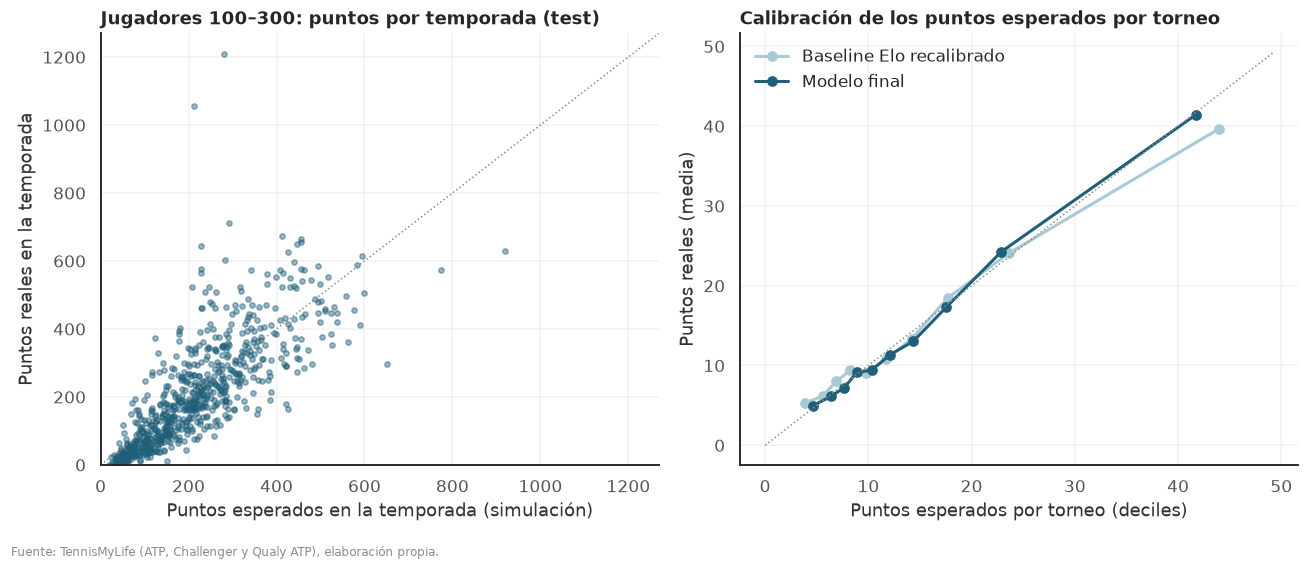

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
pts_esp_final,4.7,6.4,7.7,8.9,10.3,12.1,14.3,17.5,22.9,41.7
pts_real,5.0,6.2,7.2,9.2,9.4,11.4,13.0,17.3,24.3,41.4


In [19]:
# 5.3 Métricas de la simulación: error en puntos (MAE, RMSE, R²) a nivel torneo y a nivel temporada

def metricas_reg(real, esp):
    real, esp = np.asarray(real, float), np.asarray(esp, float)
    err = real - esp
    return {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean()),
            'R²': 1 - (err ** 2).sum() / ((real - real.mean()) ** 2).sum(), 'Sesgo (real − esperado)': err.mean()}

pob = val[val.en_poblacion]
temporada = (pob.groupby(['id', 'anio'])[['pts_real', 'pts_esp_final', 'pts_esp_base']].sum()
             .join(pob.groupby(['id', 'anio']).size().rename('torneos')))
temporada = temporada[temporada.torneos >= 5]                 # jugadores con una temporada mínimamente completa
filas_m = []
for nivel, d in [('Jugador-torneo', pob), ('Jugador-temporada (≥5 torneos)', temporada)]:
    for etiqueta, col in [('Baseline Elo recalibrado', 'pts_esp_base'), ('Modelo final', 'pts_esp_final')]:
        filas_m.append({'nivel': nivel, 'simulación con': etiqueta, 'n': len(d), 'puntos reales (media)': d.pts_real.mean(),
                        **metricas_reg(d.pts_real, d[col])})
tabla_mc = pd.DataFrame(filas_m)
display(tabla_mc.style.hide(axis='index').format({'n': '{:,}', 'puntos reales (media)': '{:.1f}', 'MAE': '{:.1f}', 'RMSE': '{:.1f}',
                                                  'R²': '{:.3f}', 'Sesgo (real − esperado)': '{:+.1f}'}))

# Calibración de los puntos esperados por temporada: real vs. esperado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
lim = max(temporada.pts_real.max(), temporada.pts_esp_final.max()) * 1.05
ax.scatter(temporada.pts_esp_final, temporada.pts_real, s=12, alpha=.45, color=C_PRINCIPAL)
ax.plot([0, lim], [0, lim], color=C_GRIS, ls=':', lw=1)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.grid(True, axis='both', alpha=.25)
ax.set_xlabel('Puntos esperados en la temporada (simulación)'); ax.set_ylabel('Puntos reales en la temporada')
ax.set_title('Jugadores 100–300: puntos por temporada (test)')
ax = axes[1]
q = pd.qcut(pob.pts_esp_final, 10, duplicates='drop')
for etiqueta, col, color in [('Baseline Elo recalibrado', 'pts_esp_base', C_SECUNDARIO), ('Modelo final', 'pts_esp_final', C_PRINCIPAL)]:
    qq = pd.qcut(pob[col], 10, duplicates='drop')
    c = pob.groupby(qq, observed=True)[[col, 'pts_real']].mean()
    ax.plot(c[col], c.pts_real, marker='o', lw=2, color=color, label=etiqueta)
mx = pob[['pts_esp_final', 'pts_esp_base']].groupby(q, observed=True).mean().max().max() * 1.15
ax.plot([0, mx], [0, mx], color=C_GRIS, ls=':', lw=1)
ax.set_xlabel('Puntos esperados por torneo (deciles)'); ax.set_ylabel('Puntos reales (media)')
ax.set_title('Calibración de los puntos esperados por torneo'); ax.legend(loc='upper left'); ax.grid(True, axis='both', alpha=.25)
cerrar('25_validacion_montecarlo')
deciles = pob.groupby(pd.qcut(pob.pts_esp_final, 10, duplicates='drop'), observed=True)[['pts_esp_final', 'pts_real']].mean()
deciles.index = [f'D{i + 1}' for i in range(len(deciles))]
display(deciles.T.round(1))

## 6. Optimización del calendario

Para cada argentino de ranking 100–300 se calculan los puntos esperados en cada torneo elegible del calendario 2026 y se elige el calendario que los maximiza.

**Supuestos.**
- El nivel del jugador es el actual (último partido registrado) para toda la temporada.
- El cuadro de cada torneo es el de su edición más reciente: el real de 2026 para los torneos ya jugados.
- La elegibilidad sale del corte de ingreso estimado. En ATP, si el ranking no alcanza para el cuadro principal pero sí para la qualy, se simula también la clasificación. En Challenger la qualy no se simula, porque la fuente no la registra.
- A lo sumo 4 semanas seguidas de competencia. Cada cambio de región se penaliza como costo de viaje (10 puntos; se informa la sensibilidad).
- La comparación con el calendario real usa la misma cantidad de torneos y el mismo período (enero–octubre de 2026), así la diferencia mide solo la elección de torneos.

In [20]:
# 6.1 Jugadores a recomendar: argentinos de ranking 100–300 activos al corte de datos
# El estado de cada jugador (Elo general y por superficie, ranking, forma, saque) es el de su último partido registrado.

ult = L.sort_values('match_uid').groupby('id').tail(1).set_index('id')
activos = ult[ult.ioc.astype(object).eq(PAIS_FOCO) & ult['rank'].between(RANK_MIN, RANK_MAX)
              & ult.tourney_date.ge(FECHA_CORTE - pd.Timedelta(days=70))]
JUGADORES = activos.sort_values('rank').index.tolist()

def estado_jugador(pid):
    """Atributos del jugador para un torneo hipotético: su último estado conocido."""
    filas = L[L.id.eq(pid)].sort_values('match_uid')
    a = ATRIB_ALL.loc[filas.index[-1], ATRIB_JUG].copy()
    a['dias_descanso'], a['inactivo_8s'], a['primer_evento'], a['partidos_en_evento'] = 14, 0, 0, 0
    a['clasificado'] = a['wild_card'] = a['lucky_loser'] = a['cabeza_serie'] = 0
    elo_sup = filas.groupby('surface_elo').elo_sup.last()              # último Elo en cada superficie
    return a, elo_sup.to_dict(), filas.ioc.iloc[-1]

ESTADO = {pid: estado_jugador(pid) for pid in JUGADORES}
tabla_jug = pd.DataFrame([{
    'jugador': ult.loc[p, 'name'], 'ranking': int(ult.loc[p, 'rank']), 'puntos ATP': ult.loc[p, 'rank_points'],
    'edad': round(ESTADO[p][0]['edad'], 1), 'Elo': round(ESTADO[p][0]['elo']),
    'Elo polvo': round(ESTADO[p][1].get('Clay', np.nan)), 'Elo cemento': round(ESTADO[p][1].get('Hard', np.nan)),
    'último partido': ult.loc[p, 'tourney_date'].date()} for p in JUGADORES])
print(f'Argentinos de ranking {RANK_MIN}–{RANK_MAX} activos al {FECHA_CORTE.date()}: {len(JUGADORES)}')
display(tabla_jug.style.hide(axis='index').format({'puntos ATP': '{:,.0f}'}))

Argentinos de ranking 100–300 activos al 2026-10-19: 9


jugador,ranking,puntos ATP,edad,Elo,Elo polvo,Elo cemento,último partido
Francisco Comesana,125,482,26.000000,1847,1821,1804,2026-10-12
Guido Ivan Justo,188,307,28.800000,1764,1752,1432,2026-10-12
Facundo Mena,197,298,34.100000,1710,1711,1513,2026-10-12
Federico Agustin Gomez,204,290,29.900000,1716,1709,1617,2026-10-05
Lautaro Midon,206,289,22.500000,1783,1776,1674,2026-10-05
Alex Barrena,224,260,24.000000,1741,1718,1458,2026-10-12
Juan Bautista Torres,279,202,24.500000,1608,1574,1478,2026-10-12
Juan Manuel La Serna,285,198,22.700000,1737,1725,1630,2026-10-12
Genaro Alberto Olivieri,287,197,28.200000,1686,1661,1481,2026-10-12


In [21]:
# 6.2 Cuadro típico y corte de ingreso de cada torneo del calendario 2026
# - Cuadro típico: los jugadores que jugaron la edición más reciente del torneo (la de 2026 si ya se jugó), con sus
#   atributos al comienzo de esa edición. Para los torneos sin ediciones en la base se usa la edición más reciente de
#   otro torneo de la misma categoría y superficie.
# - Corte de ingreso al cuadro principal: ranking del jugador ubicado en la posición del 80% del cuadro (ATP) o del 75%
#   (Challenger), que aproxima al último aceptado en forma directa. La forma de ingreso no sirve para esto: en 2026 la
#   fuente no la registra y en Challenger nunca lo hace.
# - Qualy (solo ATP): corte = percentil 75 del ranking de la qualy; cantidad de rondas = las de esa edición.

N_SIM_CAL = 1000
mains = L[L.circuito.isin(['ATP cuadro principal', 'Challenger'])]
qualys = L[L.circuito.eq('Qualy ATP')]
ultima_ed = mains.groupby('id_atp').tourney_id.max()                    # tourney_id = 'AAAA-id': el máximo es el más reciente
ed_por_clave = (mains.assign(clave=mains.id_atp.map(CLAVE_TORNEO)).groupby(['clave', 'surface_elo']).tourney_id.max())

def campo_de(tid):
    g = mains[mains.tourney_id.eq(tid)].sort_values('match_uid')
    primero = g.drop_duplicates('id')
    return primero.reset_index().rename(columns={'index': 'fila_L'})

sim_cal = calendario_2026[calendario_2026.simulable].copy()
CAMPOS = {}
for t in sim_cal.itertuples():
    tid = ultima_ed.get(t.id_atp)
    origen = 'misma sede'
    if tid is None:
        tid = ed_por_clave.get((t.categoria_puntos, t.superficie_elo), ed_por_clave.xs(t.categoria_puntos, level=0).max()
                               if t.categoria_puntos in ed_por_clave.index.get_level_values(0) else None)
        origen = 'misma categoría'
    if tid is None:
        continue
    campo = campo_de(tid)
    cuadro = int(t.cuadro) if pd.notna(t.cuadro) else len(campo)
    campo = campo.sort_values('rank', na_position='last').head(max(cuadro, 2)).reset_index(drop=True)
    es_atp = t.circuito == 'ATP'
    rk = campo['rank'].dropna().sort_values()
    corte_md = rk.iloc[min(max(int((0.80 if es_atp else 0.75) * cuadro) - 1, 0), len(rk) - 1)] if len(rk) else np.nan
    q = qualys[qualys.tourney_id.eq(tid)]
    corte_q, rondas_q, campo_q = np.nan, 0, None
    if es_atp and len(q):
        campo_q = q.sort_values('match_uid').drop_duplicates('id').reset_index().rename(columns={'index': 'fila_L'})
        corte_q = campo_q['rank'].quantile(.75)
        rondas_q = int(q['round'].astype(str).str.extract(r'Q(\d)')[0].astype(float).max())
    ctx = {'sup_polvo': int(t.superficie_elo == 'Clay'), 'sup_cesped': int(t.superficie_elo == 'Grass'),
           'circ_challenger': int(t.circuito == 'Challenger'), 'circ_qualy': 0, 'bo5': int(t.categoria_puntos == 'GS')}
    slots = int(2 ** np.ceil(np.log2(max(cuadro, len(campo)))))
    rondas = rondas_cuadro(slots)
    attrs = ATRIB_ALL.loc[campo.fila_L, ATRIB_JUG].reset_index(drop=True)
    CAMPOS[t.id_atp] = dict(tid=tid, origen=origen, campo=campo, attrs=attrs, cuadro=cuadro, rondas=rondas, ctx=ctx,
                            P=matriz_prob(attrs, ctx, rondas, predictor_final), corte_md=corte_md, corte_q=corte_q,
                            rondas_q=rondas_q, campo_q=campo_q)

resumen_campos = pd.DataFrame([{'id_atp': k, 'edición usada': v['tid'], 'origen': v['origen'], 'jugadores': len(v['campo']),
                                'corte cuadro principal': v['corte_md'], 'corte qualy': v['corte_q'], 'rondas de qualy': v['rondas_q']}
                               for k, v in CAMPOS.items()])
resumen_campos = sim_cal[['id_atp', 'nombre', 'categoria_puntos']].merge(resumen_campos, on='id_atp')
print(f'Torneos con cuadro típico: {len(CAMPOS)} de {len(sim_cal)} simulables '
      f"({(resumen_campos.origen == 'misma categoría').sum()} con la edición de otro torneo de la misma categoría)")
display(resumen_campos.groupby('categoria_puntos').agg(torneos=('id_atp', 'size'), corte_md_mediano=('corte cuadro principal', 'median'),
                                                       corte_qualy_mediano=('corte qualy', 'median')).round(0))

Torneos con cuadro típico: 320 de 320 simulables (19 con la edición de otro torneo de la misma categoría)


,torneos,corte_md_mediano,corte_qualy_mediano
categoria_puntos,,,
ATP250_32,28,134.0,282.0
ATP250_48,1,123.0,653.0
ATP500_32,16,92.0,213.0
CH100,33,331.0,NaN
CH125,39,314.0,NaN
CH175,6,146.0,NaN
CH50,80,549.0,NaN
CH75,104,431.0,NaN
GS,4,116.0,223.0


In [22]:
# 6.3 Puntos esperados de cada jugador en cada torneo del calendario 2026
# El jugador entra al cuadro típico en lugar del peor rankeado (o de un clasificado, si llega por la qualy) y se simula
# el cuadro. Si su ranking no alcanza para el cuadro principal de un ATP pero sí para la qualy, se agrega la etapa de
# clasificación: probabilidad de ganar cada ronda contra el rival medio de la qualy y puntos de qualy (9.03).

def prob_vs(a, attrs_rivales, ctx, codigos_ronda, predictor=predictor_final):
    """Probabilidad de que el jugador (serie a) le gane a cada rival, por ronda: matriz (rondas, rivales)."""
    D = (a[ATRIB_JUG].values[None, :] - attrs_rivales[ATRIB_JUG].values)
    filas = []
    for cod in codigos_ronda:
        X = pd.DataFrame(D, columns=[f'd_{c}' for c in ATRIB_JUG])
        X['d_elo_x_bo5'] = X.d_elo * ctx['bo5']
        for c in ['sup_polvo', 'sup_cesped', 'circ_challenger', 'circ_qualy', 'bo5']:
            X[c] = ctx[c]
        X['ronda'] = cod
        X_inv = -X[[c for c in X.columns if c.startswith('d_')]]
        X_inv = pd.concat([X_inv, X[[c for c in X.columns if not c.startswith('d_')]]], axis=1)[X.columns]
        filas.append((predictor(X) + 1 - predictor(X_inv)) / 2)
    return np.array(filas)

def atributos_en(pid, t, via_qualy, rondas_q=0):
    a, elo_sup, ioc = ESTADO[pid]
    a = a.copy()
    a['elo_sup'] = elo_sup.get(t.superficie_elo, a['elo'])
    a['es_local'] = int(ioc == t.pais_ioc)
    a['clasificado'] = int(via_qualy)
    a['partidos_en_evento'] = rondas_q if via_qualy else 0
    return a

def esperado(pid, t, via_qualy, rng):
    """Puntos esperados (y probabilidad de clasificar) del jugador en el torneo t por el camino indicado."""
    c = CAMPOS[t.id_atp]
    campo = c['campo']
    rank_j = ult.loc[pid, 'rank']
    fuera = campo.index[campo.id.eq(pid)].tolist()                      # si jugó esa edición, se lo saca
    otros = campo.index[~campo.index.isin(fuera)]                       # campo ordenado por ranking
    q_idx = otros[campo.loc[otros, 'entry'].astype(object).eq('Q')] if via_qualy else []
    sale = fuera or ([q_idx[-1]] if len(q_idx) else [otros[-1]])        # deja su lugar el peor rankeado (o un clasificado)
    quedan = np.setdiff1d(campo.index, sale)
    a = atributos_en(pid, t, via_qualy, c['rondas_q'])
    rank_campo = np.append(campo.loc[quedan, 'rank'].values, rank_j)
    k = n_cabezas(c['cuadro'])
    a['cabeza_serie'] = int((rank_campo[:-1] < rank_j).sum() < k) if not via_qualy else 0
    pv = prob_vs(a, c['attrs'].loc[quedan], c['ctx'], [CODIGO_RONDA[r] for r in c['rondas']])
    n = len(quedan) + 1
    P = np.full((len(c['rondas']), n, n), 0.5)
    P[:, :-1, :-1] = c['P'][:, quedan][:, :, quedan]
    P[:, -1, :-1], P[:, :-1, -1] = pv, 1 - pv
    perdio, bye, rondas = simular_cuadro(P, rank_campo, c['cuadro'], N_SIM_CAL, rng)
    clasif = np.zeros(n, int); clasif[-1] = int(via_qualy)
    e_md = puntos_de_ronda(perdio[:, [-1]], bye[:, [-1]], rondas, t.categoria_puntos, clasif[[-1]]).mean()
    if not via_qualy:
        return e_md, 1.0
    cq = c['campo_q']
    ctx_q = {**c['ctx'], 'circ_qualy': 1}
    aq = atributos_en(pid, t, False); aq['clasificado'] = 0
    pq = prob_vs(aq, ATRIB_ALL.loc[cq.fila_L, ATRIB_JUG].reset_index(drop=True), ctx_q,
                 list(range(1, c['rondas_q'] + 1))).mean(1)                     # rival medio de cada ronda
    llegar = np.concatenate([[1], np.cumprod(pq)])                              # prob. de llegar a cada ronda
    fila = puntos.loc[t.categoria_puntos]
    e_q = 0.0
    if c['rondas_q'] >= 1:
        e_q += llegar[-2] * (1 - pq[-1]) * np.nan_to_num(fila['Q_pierde_ult_ronda'])
    if c['rondas_q'] >= 2:
        e_q += llegar[-3] * (1 - pq[-2]) * np.nan_to_num(fila['Q_pierde_penult_ronda'])
    return llegar[-1] * e_md + e_q, llegar[-1]

t0 = time.time()
rng = np.random.default_rng(SEED)
filas_e = []
for pid in JUGADORES:
    rank_j = ult.loc[pid, 'rank']
    for t in sim_cal.itertuples():
        if t.id_atp not in CAMPOS:
            continue
        c = CAMPOS[t.id_atp]
        caminos = []
        if pd.notna(c['corte_md']) and rank_j <= c['corte_md']:
            caminos.append(False)
        elif t.circuito == 'ATP' and c['campo_q'] is not None and pd.notna(c['corte_q']) and rank_j <= c['corte_q']:
            caminos.append(True)
        for via_q in caminos:
            e, p_cl = esperado(pid, t, via_q, rng)
            filas_e.append({'id': pid, 'id_atp': t.id_atp, 'via_qualy': via_q, 'puntos_esperados': e, 'prob_clasificar': p_cl})
E = pd.DataFrame(filas_e).merge(sim_cal, on='id_atp')
E['semana_juego'] = np.where(E.via_qualy & E.categoria_puntos.eq('GS'), E.semana_qualy, E.semana_ini)
E['semanas_ocupadas'] = E.n_semanas + (E.via_qualy & E.categoria_puntos.eq('GS')).astype(int)
print(f'Combinaciones jugador-torneo elegibles: {len(E):,} ({time.time() - t0:.0f} s)')
display(E.groupby('categoria_puntos').agg(opciones=('id', 'size'), puntos_esperados_medios=('puntos_esperados', 'mean'))
        .sort_values('puntos_esperados_medios', ascending=False).round(1))

Combinaciones jugador-torneo elegibles: 2,484 (115 s)


,opciones,puntos_esperados_medios
categoria_puntos,,
ATP500_32,66,13.7
CH175,9,12.8
M1000_96,11,12.7
GS,22,11.5
CH75,920,10.8
CH50,717,10.4
CH125,281,10.3
ATP250_32,178,9.9
CH100,271,9.7


In [23]:
# 6.4 Optimizador del calendario (programación dinámica semana a semana)
# Estado: semana, región del último torneo, semanas seguidas jugando y torneos jugados. En cada semana el jugador
# descansa o empieza un torneo elegible; un torneo de dos semanas (o un Grand Slam con qualy) ocupa ambas.
# Restricciones: a lo sumo MAX_SEGUIDAS semanas consecutivas y un máximo de torneos.
# Objetivo: maximizar los puntos esperados, con una penalización opcional (lambda_viaje, en puntos) por cada cambio de
# región, que representa el costo de un viaje largo.

MAX_SEGUIDAS = 4
REGIONES = ['Sudamerica', 'Norteamerica', 'Europa', 'Asia', 'Oceania', 'Africa']
REGIONES_IDX = {r: i for i, r in enumerate(REGIONES)}
SIN_REGION = len(REGIONES)                                      # estado inicial: todavía no jugó
SEMANAS = pd.date_range(min(E.semana_juego.min(), calendario_2026.semana_ini.min()),
                        calendario_2026.semana_ini.max() + pd.Timedelta(weeks=2), freq='7D')
SEM_IDX = {s: i for i, s in enumerate(SEMANAS)}
E['w'] = E.semana_juego.map(SEM_IDX)
E['r'] = E.region.map(REGIONES_IDX).fillna(SIN_REGION).astype(int)

def optimizar(opc, max_torneos, lambda_viaje=0.0, w_ini=0, w_fin=None, region_ini=SIN_REGION, seguidas_ini=0):
    """Calendario que maximiza los puntos esperados entre las semanas [w_ini, w_fin). Devuelve las filas elegidas."""
    w_fin = len(SEMANAS) if w_fin is None else w_fin
    R, C, N = SIN_REGION + 1, MAX_SEGUIDAS + 1, max_torneos + 1
    V = np.zeros((w_fin + 1, R, C, N))
    decision = {}
    por_semana = {w: g for w, g in opc[(opc.w >= w_ini) & (opc.w < w_fin)].groupby('w')}
    viaje = lambda r_dest: np.where((np.arange(R) != r_dest) & (np.arange(R) != SIN_REGION), lambda_viaje, 0.0)
    for w in range(w_fin - 1, w_ini - 1, -1):
        mejor = np.repeat(V[w + 1][:, [0], :], C, axis=1)       # descansar: se cortan las semanas seguidas
        eleccion = np.full((R, C, N), -1)
        for idx, o in por_semana.get(w, opc.iloc[:0]).iterrows():
            d, fin = int(o.semanas_ocupadas), min(w + int(o.semanas_ocupadas), w_fin)
            for c in range(C):
                if c + d > MAX_SEGUIDAS:
                    continue
                futuro = V[fin][o.r, min(c + d, MAX_SEGUIDAS), 1:]
                valor = np.concatenate([o.puntos_esperados - viaje(o.r)[:, None] + futuro[None, :],
                                        np.full((R, 1), -np.inf)], axis=1)
                mejora = valor > mejor[:, c, :]
                mejor[:, c, :] = np.where(mejora, valor, mejor[:, c, :])
                eleccion[:, c, :] = np.where(mejora, idx, eleccion[:, c, :])
        V[w], decision[w] = mejor, eleccion
    w, r, c, n, elegidos = w_ini, region_ini, seguidas_ini, 0, []
    while w < w_fin:
        e = decision[w][r, c, n]
        if e < 0:
            w, c = w + 1, 0
            continue
        o = opc.loc[e]
        elegidos.append(e)
        w, r, c, n = w + int(o.semanas_ocupadas), int(o.r), min(c + int(o.semanas_ocupadas), MAX_SEGUIDAS), n + 1
    return opc.loc[elegidos]

def mejor_por_semana(opc, semanas):
    """En las mismas semanas en que jugó, el torneo elegible con más puntos esperados."""
    g = opc[opc.semana_juego.isin(semanas)]
    return g.loc[g.groupby('semana_juego').puntos_esperados.idxmax()]

def heuristica(opc, semanas):
    """Regla de referencia de la propuesta inicial, en las mismas semanas: polvo de ladrillo primero, después la mayor
    categoría y, a igualdad, la misma región del torneo anterior."""
    elegidos, region_prev = [], None
    for s in sorted(semanas):
        g = opc[opc.semana_juego.eq(s)]
        if g.empty:
            continue
        g = g.assign(polvo=g.superficie_elo.eq('Clay').astype(int), nivel=g.categoria_puntos.map(puntos.W),
                     misma=g.region.eq(region_prev).astype(int)).sort_values(['polvo', 'nivel', 'misma'], ascending=False)
        elegidos.append(g.index[0]); region_prev = g.region.iloc[0]
    return opc.loc[elegidos]

def resumen_calendario(c):
    regiones = c.sort_values('w').region.tolist()
    return {'torneos': len(c), 'puntos esperados': c.puntos_esperados.sum(),
            'cambios de región': sum(a != b for a, b in zip(regiones, regiones[1:])),
            '% polvo': c.superficie_elo.eq('Clay').mean() if len(c) else np.nan,
            '% Challenger': c.circuito.eq('Challenger').mean() if len(c) else np.nan}

In [24]:
# 6.5 Calendario real 2026 vs. heurística vs. calendario optimizado (enero–octubre, mismo número de torneos)
# Los tres calendarios se valoran con la misma simulación y con el nivel actual del jugador, así la diferencia mide
# solo la elección de torneos. Comparaciones:
# - Heurística: la regla de la propuesta inicial, en las mismas semanas en que el jugador jugó.
# - Óptimo (mismas semanas): el mejor torneo elegible en cada una de esas semanas.
# - Óptimo (libre): la programación dinámica elige semanas y torneos, con la misma cantidad de torneos y una
#   penalización por viaje de LAMBDA_VIAJE puntos por cada cambio de región.

LAMBDA_VIAJE = 10
W_CORTE = SEM_IDX[FECHA_CORTE - pd.Timedelta(days=FECHA_CORTE.weekday())]

def eventos_reales(pid):
    """Torneos que jugó en 2026 hasta el corte, con el camino (qualy o cuadro principal) que siguió."""
    g = L[L.id.eq(pid) & L.anio.eq(2026)]
    ev_ = g.groupby('id_atp').agg(via_qualy=('es_qualy', 'max'), circuito=('circuito', 'first')).reset_index()
    ev_['via_qualy'] = ev_.via_qualy.astype(bool) & ev_.circuito.ne('Challenger')
    return ev_[ev_.id_atp.isin(CAMPOS)]

filas_k, cal_real, cal_opt = [], {}, {}
rng = np.random.default_rng(SEED)
for pid in JUGADORES:
    opc = E[E.id.eq(pid) & (E.w < W_CORTE)]
    reales = []
    for ev_r in eventos_reales(pid).itertuples():
        fila = E[E.id.eq(pid) & E.id_atp.eq(ev_r.id_atp) & E.via_qualy.eq(ev_r.via_qualy)]
        if len(fila):
            reales.append(fila.iloc[0])
            continue
        if ev_r.via_qualy and CAMPOS[ev_r.id_atp]['campo_q'] is None:
            continue
        t = next(sim_cal[sim_cal.id_atp.eq(ev_r.id_atp)].itertuples())      # hoy no sería elegible por ese camino
        e, p_cl = esperado(pid, t, ev_r.via_qualy, rng)
        gs_q = ev_r.via_qualy and t.categoria_puntos == 'GS'
        reales.append(pd.Series({**t._asdict(), 'id': pid, 'via_qualy': ev_r.via_qualy, 'puntos_esperados': e,
                                 'prob_clasificar': p_cl, 'semana_juego': t.semana_qualy if gs_q else t.semana_ini,
                                 'semanas_ocupadas': t.n_semanas + int(gs_q)}))
    real = pd.DataFrame(reales)
    real['w'] = real.semana_juego.map(SEM_IDX)
    real = real[real.w < W_CORTE]
    semanas_real = set(real.semana_juego)
    heur, sem = heuristica(opc, semanas_real), mejor_por_semana(opc, semanas_real)
    libre = optimizar(opc, max_torneos=len(real), lambda_viaje=LAMBDA_VIAJE, w_fin=W_CORTE)
    cal_real[pid], cal_opt[pid] = real, libre
    for nombre, c in [('Real', real), ('Heurística (mismas semanas)', heur), ('Óptimo (mismas semanas)', sem),
                      ('Óptimo (libre)', libre)]:
        filas_k.append({'id': pid, 'jugador': ult.loc[pid, 'name'], 'calendario': nombre, **resumen_calendario(c)})
comparacion = pd.DataFrame(filas_k)
tabla_k = comparacion.pivot(index='jugador', columns='calendario', values='puntos esperados')[
    ['Real', 'Heurística (mismas semanas)', 'Óptimo (mismas semanas)', 'Óptimo (libre)']]
tabla_k.loc['Total'] = tabla_k.sum()
tabla_k['Ganancia libre vs. real'] = tabla_k['Óptimo (libre)'] - tabla_k['Real']
tabla_k['Ganancia %'] = tabla_k['Ganancia libre vs. real'] / tabla_k['Real']
display(tabla_k.style.format('{:.0f}').format({'Ganancia %': '{:+.0%}', 'Ganancia libre vs. real': '{:+.0f}'}))
display(comparacion.groupby('calendario', sort=False)[['torneos', 'cambios de región', '% polvo', '% Challenger']].mean()
        .style.format({'torneos': '{:.1f}', 'cambios de región': '{:.1f}', '% polvo': '{:.0%}', '% Challenger': '{:.0%}'}))

calendario,Real,Heurística (mismas semanas),Óptimo (mismas semanas),Óptimo (libre),Ganancia libre vs. real,Ganancia %
jugador,,,,,,
Alex Barrena,326.038105,339.314308,418.668064,395.755854,+70,+21%
Facundo Mena,249.067964,196.144466,278.784036,266.815000,+18,+7%
Federico Agustin Gomez,211.021601,209.732161,307.165485,300.523345,+90,+42%
Francisco Comesana,521.682027,484.755042,641.421455,632.277564,+111,+21%
Genaro Alberto Olivieri,206.577346,232.735765,267.141188,257.785700,+51,+25%
Guido Ivan Justo,392.092918,339.707460,453.030648,416.195648,+24,+6%
Juan Bautista Torres,189.167354,181.340439,224.753701,219.215737,+30,+16%
Juan Manuel La Serna,267.642818,233.234248,302.811874,294.248000,+27,+10%
Lautaro Midon,332.023481,328.360391,420.701249,423.356000,+91,+28%


,torneos,cambios de región,% polvo,% Challenger
calendario,,,,
Real,25.4,4.1,84%,81%
Heurística (mismas semanas),25.4,4.6,98%,79%
Óptimo (mismas semanas),25.4,15.1,70%,89%
Óptimo (libre),25.4,1.4,86%,94%


jugador,ranking actual,puntos actuales,puntos esperados (real),puntos esperados (óptimo),ganancia de puntos,ranking equivalente,cambios de región (real → óptimo),puestos ganados
Francisco Comesana,125,482,522,632,+111,105,6 → 3,+20
Guido Ivan Justo,188,307,392,416,+24,171,5 → 1,+17
Facundo Mena,197,298,249,267,+18,184,6 → 1,+13
Federico Agustin Gomez,204,290,211,301,+90,148,4 → 2,+56
Lautaro Midon,206,289,332,423,+91,148,3 → 2,+58
Alex Barrena,224,260,326,396,+70,173,3 → 1,+51
Juan Bautista Torres,279,202,189,219,+30,242,2 → 1,+37
Juan Manuel La Serna,285,198,268,294,+27,252,2 → 1,+33
Genaro Alberto Olivieri,287,197,207,258,+51,232,6 → 1,+55


Ganancia media: +57 puntos por jugador (+19%), equivalente a +37 puestos de ranking (mediana)


penalización por viaje (puntos),puntos esperados (total),cambios de región por jugador
0,3576,15.0
10,3206,1.4
25,3113,0.8
50,2909,0.1


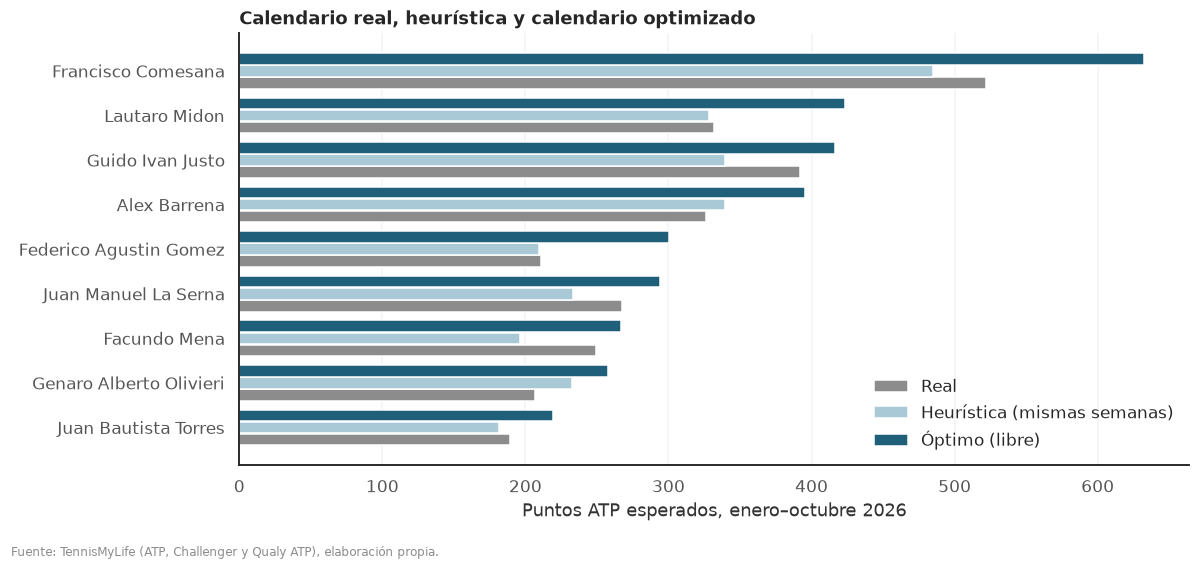

In [25]:
# 6.6 Indicadores de negocio: puntos, puestos de ranking y viajes
# Puestos de ranking: con la curva puntos → ranking de las últimas 8 semanas, se ubica a cada jugador con sus puntos
# actuales más la ganancia esperada del calendario optimizado (el ranking ATP suma las últimas 52 semanas).

recientes = L[L.tourney_date.ge(FECHA_CORTE - pd.Timedelta(weeks=8)) & L['rank'].notna() & L.rank_points.notna()]
curva = recientes.sort_values('match_uid').groupby('id')[['rank', 'rank_points']].last().sort_values('rank_points', ascending=False)

def puesto(pts):
    return float(np.interp(-pts, -curva.rank_points.values, curva['rank'].values))

kpi = []
for pid in JUGADORES:
    fila = comparacion[comparacion.id.eq(pid)].set_index('calendario')
    gan = fila.loc['Óptimo (libre)', 'puntos esperados'] - fila.loc['Real', 'puntos esperados']
    pts_hoy = ult.loc[pid, 'rank_points']
    kpi.append({'jugador': ult.loc[pid, 'name'], 'ranking actual': int(ult.loc[pid, 'rank']), 'puntos actuales': pts_hoy,
                'puntos esperados (real)': fila.loc['Real', 'puntos esperados'],
                'puntos esperados (óptimo)': fila.loc['Óptimo (libre)', 'puntos esperados'],
                'ganancia de puntos': gan, 'ranking equivalente': puesto(pts_hoy + gan),
                'cambios de región (real → óptimo)': f"{fila.loc['Real', 'cambios de región']:.0f} → {fila.loc['Óptimo (libre)', 'cambios de región']:.0f}"})
kpi = pd.DataFrame(kpi)
kpi['puestos ganados'] = kpi['ranking actual'] - kpi['ranking equivalente']
display(kpi.style.hide(axis='index').format({'puntos actuales': '{:,.0f}', 'puntos esperados (real)': '{:.0f}',
                                             'puntos esperados (óptimo)': '{:.0f}', 'ganancia de puntos': '{:+.0f}',
                                             'ranking equivalente': '{:.0f}', 'puestos ganados': '{:+.0f}'}))
print(f"Ganancia media: {kpi['ganancia de puntos'].mean():+.0f} puntos por jugador "
      f"({kpi['ganancia de puntos'].sum() / kpi['puntos esperados (real)'].sum():+.0%}), "
      f"equivalente a {kpi['puestos ganados'].median():+.0f} puestos de ranking (mediana)")

# Sensibilidad a la penalización por viaje
sens = []
for lam in (0, 10, 25, 50):
    tot, cambios = 0.0, 0
    for pid in JUGADORES:
        opc = E[E.id.eq(pid) & (E.w < W_CORTE)]
        c = optimizar(opc, max_torneos=len(cal_real[pid]), lambda_viaje=lam, w_fin=W_CORTE)
        r = resumen_calendario(c)
        tot += r['puntos esperados']; cambios += r['cambios de región']
    sens.append({'penalización por viaje (puntos)': lam, 'puntos esperados (total)': tot,
                 'cambios de región por jugador': cambios / len(JUGADORES)})
sens = pd.DataFrame(sens)
display(sens.style.hide(axis='index').format({'puntos esperados (total)': '{:.0f}', 'cambios de región por jugador': '{:.1f}'}))

fig, ax = plt.subplots(figsize=(11, 5))
orden = kpi.sort_values('puntos esperados (óptimo)').jugador
d = comparacion.pivot(index='jugador', columns='calendario', values='puntos esperados').loc[orden]
y_pos = np.arange(len(d))
for k, (col, color) in enumerate([('Real', C_GRIS), ('Heurística (mismas semanas)', C_SECUNDARIO), ('Óptimo (libre)', C_PRINCIPAL)]):
    ax.barh(y_pos + (k - 1) * .27, d[col], height=.26, color=color, label=col)
ax.set_yticks(y_pos, d.index); ax.grid(True, axis='x', alpha=.25); ax.grid(False, axis='y')
ax.set_xlabel('Puntos ATP esperados, enero–octubre 2026')
ax.set_title('Calendario real, heurística y calendario optimizado'); ax.legend(loc='lower right')
cerrar('26_comparacion_calendarios')

In [26]:
# 6.7 Recomendación para lo que queda de la temporada 2026
# Desde la semana del corte de datos hasta el final del calendario, con el estado actual de cada jugador: región del
# último torneo y semanas seguidas que viene jugando. Máximo de torneos: los que entran en el resto de la temporada.

W_HOY = W_CORTE
TORNEOS_RESTO = 6
recomendaciones = []
for pid in JUGADORES:
    real = cal_real[pid].sort_values('w')
    region_ini = REGIONES_IDX.get(real.region.iloc[-1], SIN_REGION) if len(real) else SIN_REGION
    jugadas = set(real.w)
    seguidas = 0
    while (W_HOY - 1 - seguidas) in jugadas and seguidas < MAX_SEGUIDAS:
        seguidas += 1
    opc = E[E.id.eq(pid) & (E.w >= W_HOY)]
    plan = optimizar(opc, max_torneos=TORNEOS_RESTO, lambda_viaje=LAMBDA_VIAJE, w_ini=W_HOY,
                     region_ini=region_ini, seguidas_ini=seguidas)
    for o in plan.sort_values('w').itertuples():
        recomendaciones.append({'jugador': ult.loc[pid, 'name'], 'semana': o.semana_ini.date(), 'torneo': o.nombre,
                                'sede': f'{o.ciudad} ({o.pais_ioc})', 'categoría': o.categoria_puntos,
                                'superficie': NOMBRE_SUP.get(o.superficie_elo, o.superficie_elo),
                                'ingreso': 'qualy' if o.via_qualy else 'cuadro principal',
                                'puntos esperados': o.puntos_esperados})
recomendaciones = pd.DataFrame(recomendaciones)
resumen_rec = recomendaciones.groupby('jugador', sort=False).agg(torneos=('torneo', 'size'), puntos_esperados=('puntos esperados', 'sum'))
display(resumen_rec.style.format({'puntos_esperados': '{:.0f}'}))
display(recomendaciones.style.hide(axis='index').format({'puntos esperados': '{:.1f}'}))
recomendaciones.to_csv(OUT_DIR / 'recomendaciones_resto_2026.csv', index=False, encoding='utf-8-sig')
kpi.to_csv(OUT_DIR / 'kpis_calendario.csv', index=False, encoding='utf-8-sig')

,torneos,puntos_esperados
jugador,,
Francisco Comesana,6,137
Guido Ivan Justo,6,92
Facundo Mena,6,73
Federico Agustin Gomez,6,74
Lautaro Midon,6,106
Alex Barrena,6,82
Juan Bautista Torres,6,50
Juan Manuel La Serna,6,79
Genaro Alberto Olivieri,6,53


jugador,semana,torneo,sede,categoría,superficie,ingreso,puntos esperados
Francisco Comesana,2026-10-19,Kia Open,Cali (COL),CH75,Polvo de ladrillo,cuadro principal,18.9
Francisco Comesana,2026-10-26,Challenger Ciudad de Guayaquil,Guayaquil (ECU),CH75,Polvo de ladrillo,cuadro principal,27.1
Francisco Comesana,2026-11-23,Florianopolis,Florianopolis (BRA),CH75,Polvo de ladrillo,cuadro principal,22.7
Francisco Comesana,2026-11-30,Challenger Seguros del Estado,Bogota (COL),CH75,Polvo de ladrillo,cuadro principal,27.5
Francisco Comesana,2026-12-07,Copenhagen,Copenhagen (DEN),CH50,Cemento,cuadro principal,20.8
Francisco Comesana,2026-12-14,Guanzate,Guanzate (ITA),CH50,Cemento,cuadro principal,20.0
Guido Ivan Justo,2026-10-26,Challenger Ciudad de Guayaquil,Guayaquil (ECU),CH75,Polvo de ladrillo,cuadro principal,21.3
Guido Ivan Justo,2026-11-02,Villa Maria,Villa Maria (ARG),CH50,Polvo de ladrillo,cuadro principal,10.9
Guido Ivan Justo,2026-11-23,Florianopolis,Florianopolis (BRA),CH75,Polvo de ladrillo,cuadro principal,18.4
Guido Ivan Justo,2026-11-30,Challenger Seguros del Estado,Bogota (COL),CH75,Polvo de ladrillo,cuadro principal,22.3


## 7. Conclusiones

In [27]:
# @title Conclusiones { display-mode: "form" }

def fila_test(sub, modelo_prefijo):
    f = tabla_test[tabla_test.subconjunto.str.startswith(sub) & tabla_test.modelo.str.startswith(modelo_prefijo)]
    return f.iloc[0]

pob_b, pob_f = fila_test('Población', 'Elo'), fila_test('Población', 'LightGBM')
ch_b, ch_f = fila_test('Challenger', 'Elo'), fila_test('Challenger', 'LightGBM')
lr_pob = fila_test('Población', 'Regresión')
saque = res_valid.set_index(['modelo', 'atributos', 'train'])['Log-Loss valid']
mc_t = tabla_mc.set_index(['nivel', 'simulación con'])
temp_f, temp_b = mc_t.loc[('Jugador-temporada (≥5 torneos)', 'Modelo final')], mc_t.loc[('Jugador-temporada (≥5 torneos)', 'Baseline Elo recalibrado')]
tot = tabla_k.loc['Total']
cambios = comparacion.groupby('calendario')['cambios de región'].mean()
polvo = comparacion.groupby('calendario')['% polvo'].mean()
txt = []
txt.append(f"**1. Modelo de probabilidad.** El modelo final (LightGBM con calibración de Platt) mejora al baseline Elo recalibrado "
           f"en la población objetivo (test 2024–2026): Log-Loss **{pob_f['Log-Loss']:.3f}** contra {pob_b['Log-Loss']:.3f} "
           f"(IC 95% de la diferencia: {ic_ll[0]:+.4f} a {ic_ll[1]:+.4f}), Brier {pob_f['Brier']:.3f} contra {pob_b['Brier']:.3f}, "
           f"AUC-ROC {pob_f['AUC-ROC']:.3f} contra {pob_b['AUC-ROC']:.3f} y pendiente de calibración {pob_f['Pendiente calib.']:.2f} "
           f"contra {pob_b['Pendiente calib.']:.2f}. Se cumplen {(objetivos.cumple.iloc[:4] == 'Sí').sum()} de los 4 objetivos reformulados "
           f"(notebook 01, sección 9.1). "
           f"Los umbrales absolutos de la propuesta inicial (AUC > 0.72, Log-Loss < 0.60) siguen fuera de alcance para una población "
           f"que juega sobre todo Challengers, donde el AUC es {ch_f['AUC-ROC']:.3f}.")
txt.append(f"**2. Parsimonia.** La regresión logística logra un Log-Loss de {lr_pob['Log-Loss']:.3f}, muy cerca del modelo final: la mayor "
           f"parte de la mejora viene de los atributos (ranking, descanso, carga, edad, forma de ingreso, experiencia) y no de la "
           f"complejidad del algoritmo. Se eligió LightGBM porque tiene el menor Log-Loss en validación y queda mejor calibrado, y "
           f"SHAP permite explicar sus predicciones. El saque histórico (modelo B, solo temporadas con cobertura completa) aporta una "
           f"mejora pequeña pero consistente en los tres algoritmos.")
cv = curvas.set_index(['modelo', 'n'])
lr_v, lg_v = cv.loc['Regresión logística'], cv.loc['LightGBM']
txt.append(f"**3. Sesgo y varianza.** En la regresión logística el Log-Loss de validación casi no cambia con más datos "
           f"({lr_v['Validación'].iloc[0]:.3f} → {lr_v['Validación'].iloc[-1]:.3f}): el modelo está limitado por sesgo. En LightGBM "
           f"la brecha entre train y validación se achica de {lg_v['Validación'].iloc[0] - lg_v['Train'].iloc[0]:.3f} a "
           f"{lg_v['Validación'].iloc[-1] - lg_v['Train'].iloc[-1]:.3f} y la validación sigue bajando "
           f"({lg_v['Validación'].iloc[0]:.3f} → {lg_v['Validación'].iloc[-1]:.3f}): la varianza está controlada por la detención "
           f"temprana y la regularización, y el modelo se beneficiaría de más datos.")
txt.append(f"**4. Simulación.** Con el modelo final, los puntos esperados por temporada de los jugadores 100–300 explican el "
           f"**{temp_f['R²']:.0%}** de la variabilidad de los puntos reales (RMSE {temp_f['RMSE']:.0f} puntos, sesgo "
           f"{temp_f['Sesgo (real − esperado)']:+.0f}), contra el {temp_b['R²']:.0%} con el Elo. A nivel de torneo individual el R² es bajo "
           f"porque cada resultado tiene mucho azar; por deciles de puntos esperados, la media real acompaña a la esperada "
           f"(diferencia máxima de {(deciles.pts_real - deciles.pts_esp_final).abs().max():.1f} puntos por torneo).")
txt.append(f"**5. Calendario.** Valorados con la misma simulación y el nivel actual, los calendarios optimizados de los "
           f"{len(JUGADORES)} argentinos de ranking 100–300 suman **{tot['Óptimo (libre)']:.0f} puntos esperados** entre enero y "
           f"octubre de 2026, contra {tot['Real']:.0f} de los calendarios que jugaron (**{tot['Ganancia %']:+.0%}**, con la misma "
           f"cantidad de torneos) y {tot['Heurística (mismas semanas)']:.0f} de la heurística de la propuesta inicial. La ganancia "
           f"equivale a una mediana de **{kpi['puestos ganados'].median():+.0f} puestos de ranking**, con menos viajes: "
           f"{cambios['Óptimo (libre)']:.1f} cambios de región por jugador contra {cambios['Real']:.1f}. El calendario óptimo sigue "
           f"siendo mayormente de polvo ({polvo['Óptimo (libre)']:.0%}): la ganancia no viene de abandonar el polvo sino de elegir "
           f"torneos con cuadros más accesibles para el nivel de cada jugador.")
display(Markdown('\n\n'.join(txt)))

**1. Modelo de probabilidad.** El modelo final (LightGBM con calibración de Platt) mejora al baseline Elo recalibrado en la población objetivo (test 2024–2026): Log-Loss **0.630** contra 0.640 (IC 95% de la diferencia: -0.0129 a -0.0087), Brier 0.220 contra 0.225, AUC-ROC 0.699 contra 0.685 y pendiente de calibración 1.01 contra 0.84. Se cumplen 4 de los 4 objetivos reformulados (notebook 01, sección 9.1). Los umbrales absolutos de la propuesta inicial (AUC > 0.72, Log-Loss < 0.60) siguen fuera de alcance para una población que juega sobre todo Challengers, donde el AUC es 0.687.

**2. Parsimonia.** La regresión logística logra un Log-Loss de 0.631, muy cerca del modelo final: la mayor parte de la mejora viene de los atributos (ranking, descanso, carga, edad, forma de ingreso, experiencia) y no de la complejidad del algoritmo. Se eligió LightGBM porque tiene el menor Log-Loss en validación y queda mejor calibrado, y SHAP permite explicar sus predicciones. El saque histórico (modelo B, solo temporadas con cobertura completa) aporta una mejora pequeña pero consistente en los tres algoritmos.

**3. Sesgo y varianza.** En la regresión logística el Log-Loss de validación casi no cambia con más datos (0.628 → 0.626): el modelo está limitado por sesgo. En LightGBM la brecha entre train y validación se achica de 0.189 a 0.062 y la validación sigue bajando (0.653 → 0.625): la varianza está controlada por la detención temprana y la regularización, y el modelo se beneficiaría de más datos.

**4. Simulación.** Con el modelo final, los puntos esperados por temporada de los jugadores 100–300 explican el **60%** de la variabilidad de los puntos reales (RMSE 100 puntos, sesgo -6), contra el 58% con el Elo. A nivel de torneo individual el R² es bajo porque cada resultado tiene mucho azar; por deciles de puntos esperados, la media real acompaña a la esperada (diferencia máxima de 1.4 puntos por torneo).

**5. Calendario.** Valorados con la misma simulación y el nivel actual, los calendarios optimizados de los 9 argentinos de ranking 100–300 suman **3206 puntos esperados** entre enero y octubre de 2026, contra 2695 de los calendarios que jugaron (**+19%**, con la misma cantidad de torneos) y 2545 de la heurística de la propuesta inicial. La ganancia equivale a una mediana de **+37 puestos de ranking**, con menos viajes: 1.4 cambios de región por jugador contra 4.1. El calendario óptimo sigue siendo mayormente de polvo (86%): la ganancia no viene de abandonar el polvo sino de elegir torneos con cuadros más accesibles para el nivel de cada jugador.

### Limitaciones

- **Fuente.** No hay partidos ITF ni qualys de Challenger, así que la inactividad observada de los jugadores de ranking 200–300 es mayor que la real y la qualy de Challenger no se simula.
- **Categorías históricas.** Se usan la categoría y la tabla de puntos vigentes para todo el historial (supuesto de escala constante). Las categorías de los torneos que ya no se juegan se cargaron a mano.
- **Optimización retrospectiva.** Los calendarios de 2026 se comparan con los cuadros reales de ese año, que en la práctica se conocen recién con la lista de aceptación (unas tres semanas antes). Por eso la ganancia es una cota optimista de lo que se puede capturar.
- **Estado estático.** El nivel del jugador no evoluciona dentro de la temporada simulada, y la fatiga se modela solo con el límite de semanas seguidas, no con su efecto en la probabilidad de cada partido.
- **Ranking.** El ranking ATP cuenta los mejores 19 resultados de 52 semanas. El optimizador suma todos los puntos esperados, lo que sobrevalora los torneos de menor puntaje para quienes juegan mucho.

### Trabajo futuro

- Estado dinámico en la optimización: Elo, descanso y carga que se actualicen con los resultados simulados de cada semana.
- Incorporar partidos ITF y qualys de Challenger si se consigue una fuente.
- Modelar la lista de aceptación (corte de ingreso por semana) y la regla de los mejores 19 resultados.
- Costo de viaje en dinero y premios por ronda, para optimizar el resultado económico además de los puntos.